## Cell 1 — Install libraries & check device

In [ ]:
## ── Cell 1 : Install & imports ──────────────────────────────────────────
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install monai tifffile imagecodecs gdown
!pip -q install ultralytics
!pip -q install -U scikit-image

import torch
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

import os, glob, cv2, numpy as np, tifffile as tiff
import matplotlib.pyplot as plt, matplotlib.patches as patches
import pandas as pd
from tqdm.auto import tqdm
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from monai.losses import DiceLoss
from segment_anything.utils.transforms import ResizeLongestSide

print('numpy', np.__version__)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 34.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 109.9 MB/s eta 0:00:00
Torch: 2.11.0+cu130 | CUDA: True
numpy 2.1.3


## Cell 1b — Mount Drive & set persistent checkpoint dir

Run this once per session, right after Cell 1. All checkpoint saves/loads in
Cell 7 and Cell 12 are routed through `ckpt_path(...)` so they land in Drive
and survive a runtime disconnect.

In [ ]:
## ── Cell 1b : Persist checkpoints to Google Drive (survives disconnects) ──
from google.colab import drive
drive.mount('/content/drive')

import os
CKPT_DIR = '/content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints'   # same folder on purpose: reuses Exp A (GT-box) checkpoints
os.makedirs(CKPT_DIR, exist_ok=True)

def ckpt_path(name):
    """All torch.save / torch.load / os.path.exists calls should go through this,
    so checkpoints land in Drive instead of the ephemeral runtime disk."""
    return os.path.join(CKPT_DIR, name)

print('Checkpoints will be saved to:', CKPT_DIR)
print('Existing checkpoints found:')
for f in sorted(os.listdir(CKPT_DIR)):
    print(' -', f)


Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints
Existing checkpoints found:
 - detector_seg.pth
 - detector_tra.pth
 - medsam_seg_gtbox.pth
 - medsam_seg_predbox.pth
 - medsam_seg_yolo_predbox.pth
 - medsam_tra_gtbox.pth
 - medsam_tra_predbox.pth
 - medsam_tra_yolo_predbox.pth
 - yolov8_seg.pt
 - yolov8m_tra_v2.pt


## Cell 2 — Download dataset & build pairs

We build **two** pair lists from the same DIC-C2DH-HeLa download:
- `pairs_seg` — iterates SEG silver-truth masks (Model 1)
- `pairs_tra` — iterates TRA gold-truth masks (Model 2)

In [ ]:
## ── Cell 2 : Download & build pairs ─────────────────────────────────────
!wget -q http://data.celltrackingchallenge.net/training-datasets/DIC-C2DH-HeLa.zip
!unzip -q -o DIC-C2DH-HeLa.zip -d data
ROOT = 'data/DIC-C2DH-HeLa'


# ── Model 1 pairs: anchor on ST/SEG silver-truth masks ───────────────────
def build_pairs_seg(root):
    """Each tuple: (img_path, seg_path, tra_path_or_None)"""
    pairs = []
    for seq in ['01', '02']:
        seg_dir = os.path.join(root, f'{seq}_ST', 'SEG')
        for seg_path in sorted(glob.glob(os.path.join(seg_dir, 'man_seg*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(seg_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            tra_path = os.path.join(root, f'{seq}_GT', 'TRA', f'man_track{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path,
                    tra_path if os.path.exists(tra_path) else None
                ))
    return pairs


# ── Model 2 pairs: anchor on GT/TRA gold-truth masks ─────────────────────
def build_pairs_tra(root):
    """Each tuple: (img_path, seg_path_or_None, tra_path)"""
    pairs = []
    for seq in ['01', '02']:
        tra_dir = os.path.join(root, f'{seq}_GT', 'TRA')
        for tra_path in sorted(glob.glob(os.path.join(tra_dir, 'man_track*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(tra_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            seg_dir  = os.path.join(root, f'{seq}_ST', 'SEG')
            seg_path = os.path.join(seg_dir, f'man_seg{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path if os.path.exists(seg_path) else None,
                    tra_path
                ))
    return pairs


pairs_seg = build_pairs_seg(ROOT)
pairs_tra = build_pairs_tra(ROOT)

print(f'SEG pairs : {len(pairs_seg)}')
print(f'TRA pairs : {len(pairs_tra)}  (more frames — every tracked frame is included)')

SEG pairs : 168
TRA pairs : 168  (more frames — every tracked frame is included)


## Cell 3 — Train / Val / Test split (60 / 20 / 20)

In [ ]:
## ── Cell 3 : Split ───────────────────────────────────────────────────────
def split_pairs(pairs, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(pairs))
    n   = len(pairs)
    train = [pairs[i] for i in idx[:int(.6*n)]]
    val   = [pairs[i] for i in idx[int(.6*n):int(.8*n)]]
    test  = [pairs[i] for i in idx[int(.8*n):]]
    return train, val, test

train_seg, val_seg, test_seg = split_pairs(pairs_seg)
train_tra, val_tra, test_tra = split_pairs(pairs_tra)

print(f'SEG  → train={len(train_seg)}  val={len(val_seg)}  test={len(test_seg)}')
print(f'TRA  → train={len(train_tra)}  val={len(val_tra)}  test={len(test_tra)}')

SEG  → train=100  val=34  test=34
TRA  → train=100  val=34  test=34


## Cell 3b — Split audit (leakage check) + split manifest  **[NEW]**

In [ ]:
## ── Cell 3b : Split audit (leakage check) + split manifest ───────────────────
## NEW CELL — insert directly after Cell 3. Read-only: it does NOT change the split.
import json, hashlib

def frame_key(entry):
    """'01_t012' = sequence + frame name. Same key for SEG and TRA entries."""
    img_p = entry[0]
    return f"{os.path.basename(os.path.dirname(img_p))}_{os.path.splitext(os.path.basename(img_p))[0]}"

def frame_idx(entry): return int(''.join(filter(str.isdigit, os.path.splitext(os.path.basename(entry[0]))[0])))
def frame_seq(entry): return os.path.basename(os.path.dirname(entry[0]))

def split_sha(pairs):
    return hashlib.sha1('|'.join(sorted(frame_key(e) for e in pairs)).encode()).hexdigest()[:12]

# 1) SEG and TRA must be the SAME frame partition (the SEG-vs-TRA and the Mask R-CNN comparison rely on it)
for a, b, nm in [(train_seg, train_tra, 'train'), (val_seg, val_tra, 'val'), (test_seg, test_tra, 'test')]:
    assert [frame_key(e) for e in a] == [frame_key(e) for e in b], f'SEG/TRA {nm} frames differ!'
print('✅ SEG and TRA use the identical train/val/test frame partition.')

# 2) no exact frame shared between splits
ks = {n: {frame_key(e) for e in s} for n, s in [('train', train_seg), ('val', val_seg), ('test', test_seg)]}
assert not (ks['train'] & ks['test']) and not (ks['train'] & ks['val']) and not (ks['val'] & ks['test'])
print('✅ No frame appears in two splits (exact-duplicate leakage: none).')

# 3) TEMPORAL-NEIGHBOUR leakage: how close is each held-out frame to a TRAIN frame of the same sequence?
def nearest_gap(frames, ref):
    gaps = []
    for e in frames:
        g = [abs(frame_idx(e) - frame_idx(r)) for r in ref if frame_seq(r) == frame_seq(e)]
        gaps.append(min(g) if g else 999)
    return np.array(gaps)

for nm, fr in [('test', test_seg), ('val', val_seg)]:
    g = nearest_gap(fr, train_seg)
    print(f'{nm:>4}: {int((g == 1).sum())}/{len(g)} frames have an ADJACENT train frame (t±1) | '
          f'{int((g <= 2).sum())}/{len(g)} within 2 frames | mean gap = {g.mean():.2f}')
print('⚠️  Consecutive time-lapse frames are near-duplicates (same cells, tiny motion). A random frame split\n'
      '    therefore OVERESTIMATES generalisation for every method (YOLOv8, Mask R-CNN, MedSAM) alike.\n'
      '    Numbers are valid for *comparing methods on this split*, not as absolute accuracy on new sequences.')

# 4) Persist a manifest so every notebook (this one AND the Mask R-CNN one) can prove it used the same test frames
MANIFEST = ckpt_path('split_manifest.json')
cur_manifest = dict(seed=42, rule='rng(42).permutation, 60/20/20',
                    train=sorted(ks['train']), val=sorted(ks['val']), test=sorted(ks['test']),
                    sha=dict(train=split_sha(train_seg), val=split_sha(val_seg), test=split_sha(test_seg)))
if os.path.exists(MANIFEST):
    old = json.load(open(MANIFEST))
    if old['sha'] != cur_manifest['sha']:
        raise AssertionError(f'Split differs from the manifest in {MANIFEST}. Checkpoints trained on the old split are NOT '
                             f'valid for this one. Restore the old split, or move the manifest + dependent checkpoints to an archive.')
    print('✅ Split matches the saved manifest:', cur_manifest['sha'])
else:
    json.dump(cur_manifest, open(MANIFEST, 'w'), indent=1)
    print('💾 Wrote split manifest:', MANIFEST, cur_manifest['sha'])
print('   Mask R-CNN notebook must reproduce this SAME test set before any head-to-head comparison.')


✅ SEG and TRA use the identical train/val/test frame partition.
✅ No frame appears in two splits (exact-duplicate leakage: none).
test: 24/34 frames have an ADJACENT train frame (t±1) | 33/34 within 2 frames | mean gap = 1.32
 val: 30/34 frames have an ADJACENT train frame (t±1) | 33/34 within 2 frames | mean gap = 1.15
⚠️  Consecutive time-lapse frames are near-duplicates (same cells, tiny motion). A random frame split
    therefore OVERESTIMATES generalisation for every method (YOLOv8, Mask R-CNN, MedSAM) alike.
    Numbers are valid for *comparing methods on this split*, not as absolute accuracy on new sequences.
💾 Wrote split manifest: /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/split_manifest.json {'train': 'c71e7e39c528', 'val': 'f4ef6b1b2ad5', 'test': '1ab71b23b8d7'}
   Mask R-CNN notebook must reproduce this SAME test set before any head-to-head comparison.


## Cell 4 — Visualise raw data (SEG vs TRA mask)

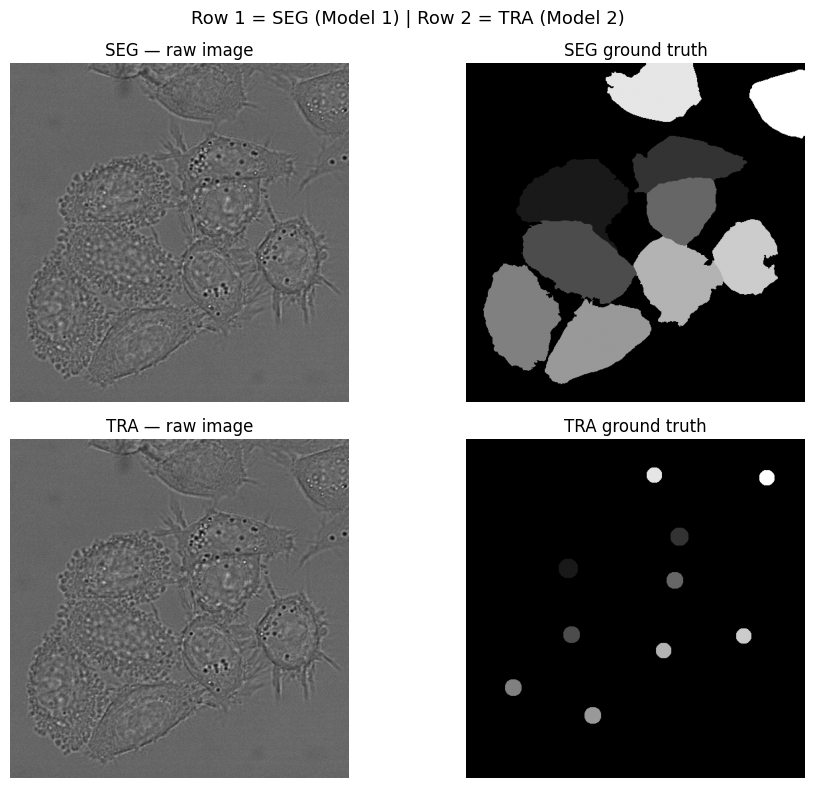

In [ ]:
## ── Cell 4 : Visualise ───────────────────────────────────────────────────
def instance_to_grayscale(mask):
    """Each instance gets a unique grayscale shade for display."""
    mask = mask.astype(np.int32)
    ids  = np.unique(mask); ids = ids[ids != 0]
    out  = np.zeros_like(mask, dtype=np.float32)
    for i, uid in enumerate(ids):
        out[mask == uid] = (i + 1) / len(ids)
    return out

# Show one SEG sample and one TRA sample side by side
img_s  = tiff.imread(pairs_seg[0][0])
seg_m  = tiff.imread(pairs_seg[0][1])

img_t  = tiff.imread(pairs_tra[0][0])
tra_m  = tiff.imread(pairs_tra[0][2])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0,0].imshow(img_s,                     cmap='gray'); axes[0,0].set_title('SEG — raw image');  axes[0,0].axis('off')
axes[0,1].imshow(instance_to_grayscale(seg_m), cmap='gray', vmin=0, vmax=1); axes[0,1].set_title('SEG ground truth'); axes[0,1].axis('off')
axes[1,0].imshow(img_t,                     cmap='gray'); axes[1,0].set_title('TRA — raw image');  axes[1,0].axis('off')
axes[1,1].imshow(instance_to_grayscale(tra_m), cmap='gray', vmin=0, vmax=1); axes[1,1].set_title('TRA ground truth'); axes[1,1].axis('off')
plt.suptitle('Row 1 = SEG (Model 1) | Row 2 = TRA (Model 2)', fontsize=13)
plt.tight_layout(); plt.show()

## Cell 5 — Shared helper functions

In [ ]:
## ── Cell 5 : Shared helpers ──────────────────────────────────────────────
transform = ResizeLongestSide(1024)

def preprocess_image(img2d):
    """Grayscale → normalised RGB float32 in [0, 255]."""
    rgb = np.repeat(img2d[..., None].astype(np.float32), 3, axis=-1)
    return (rgb - rgb.min()) / (np.ptp(rgb) + 1e-8) * 255.0

def bbox_from_mask(bm):
    """Tight bounding box [x1, y1, x2, y2] around all non-zero pixels."""
    ys, xs = np.where(bm > 0)
    if len(xs) == 0:
        return None
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def get_instance_boxes(mask):
    """One bounding box per instance ID."""
    ids = np.unique(mask); ids = ids[ids != 0]
    boxes = []
    for obj_id in ids:
        ys, xs = np.where(mask == obj_id)
        if len(xs) == 0: continue
        boxes.append((obj_id, np.array([xs.min(), ys.min(), xs.max(), ys.max()])))
    return boxes

def metrics(pred, gt):
    """Returns (Dice, IoU, Precision, Recall)."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = (pred & gt).sum()
    union = (pred | gt).sum()
    dice  = 2 * inter / (pred.sum() + gt.sum() + 1e-8)
    iou   = inter / (union + 1e-8)
    prec  = inter / (pred.sum() + 1e-8)
    rec   = inter / (gt.sum()   + 1e-8)
    return dice, iou, prec, rec

def box_iou(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter  = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-8)

print('Shared helpers defined.')

Shared helpers defined.


## Cell 6 — Load MedSAM (pretrained)

In [ ]:
## ── Cell 6 : Load MedSAM ─────────────────────────────────────────────────
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O sam_vit_b.pth

# Try Google Drive first, fall back to Hugging Face mirror if it's rate-limited/blocked
!gdown -q 1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_ -O medsam_vit_b.pth || echo 'gdown failed, trying HF mirror...'

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    print('Falling back to Hugging Face mirror...')
    !wget -q https://huggingface.co/SansuiHan/medical_models/resolve/main/medsam_vit_b.pth -O medsam_vit_b.pth

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    raise RuntimeError('MedSAM checkpoint missing or corrupt.')

from segment_anything import sam_model_registry

def load_medsam(ckpt='medsam_vit_b.pth'):
    model = sam_model_registry['vit_b'](checkpoint=None)
    model.load_state_dict(torch.load(ckpt, map_location='cpu'), strict=False)
    return model.to(DEVICE)

medsam = load_medsam()
medsam.eval()
print('MedSAM loaded:', round(os.path.getsize('medsam_vit_b.pth') / 1e6, 1), 'MB')


@torch.no_grad()
def medsam_predict(model, img2d, box):
    """Single box → binary mask."""
    H, W = img2d.shape
    img_uint8  = preprocess_image(img2d).astype(np.uint8)
    in_img     = transform.apply_image(img_uint8)
    in_t       = torch.as_tensor(in_img).permute(2, 0, 1)[None].float().to(DEVICE)
    in_t       = model.preprocess(in_t)
    emb        = model.image_encoder(in_t)

    box_arr = np.array(box, dtype=np.float32)
    box_t   = torch.as_tensor(
        transform.apply_boxes(box_arr[None], (H, W)),
        dtype=torch.float, device=DEVICE)

    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=box_t, masks=None)
    low_res, _            = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    masks    = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    pred     = torch.sigmoid(masks)[0, 0].cpu().numpy()
    return (pred > 0.5).astype(np.uint8)


@torch.no_grad()
def medsam_predict_multi(model, img2d, boxes):
    """Multiple boxes → merged binary mask (OR)."""
    H, W  = img2d.shape
    final = np.zeros((H, W), dtype=np.uint8)
    for box in boxes:
        final = np.maximum(final, medsam_predict(model, img2d, box))
    return final

MedSAM loaded: 375.0 MB


## Cell 6b — Checked MedSAM loader, batched prompting, box validator  **[NEW]**

Cell 6 loaded with `strict=False` and never looked at the result.

In [ ]:
## ── Cell 6b : MedSAM loading report, batched prompting, box validator ────────
## NEW CELL — insert directly after Cell 6.
## Why: Cell 6's load_medsam() used strict=False and never looked at the result, so a mismatching
## checkpoint would silently leave RANDOM weights in the model. This redefines load_medsam() with a report.

def load_medsam(ckpt='medsam_vit_b.pth', verbose=True):
    model = sam_model_registry['vit_b'](checkpoint=None)
    sd  = torch.load(ckpt, map_location='cpu')
    res = model.load_state_dict(sd, strict=False)
    if verbose:
        print(f'[load_medsam] {ckpt}: {len(sd)} tensors in file | missing={len(res.missing_keys)} '
              f'| unexpected={len(res.unexpected_keys)}')
    if res.missing_keys:
        raise RuntimeError(f'{len(res.missing_keys)} model tensors were NOT loaded from {ckpt} '
                           f'(they would stay randomly initialised): {res.missing_keys[:5]} ...')
    return model.to(DEVICE)

medsam = load_medsam(); medsam.eval()          # re-load the pretrained model through the checked loader


@torch.no_grad()
def medsam_predict_boxes(model, img2d, boxes, chunk=16):
    """Same maths as medsam_predict(), but the (expensive) image embedding is computed ONCE for all boxes.
    boxes: list of inclusive [x1,y1,x2,y2] pixel boxes. Returns uint8 array (N, H, W): one mask per box."""
    H, W  = img2d.shape[:2]
    boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
    if len(boxes) == 0:
        return np.zeros((0, H, W), np.uint8)
    in_img     = transform.apply_image(preprocess_image(img2d).astype(np.uint8))
    in_t       = torch.as_tensor(in_img).permute(2, 0, 1)[None].float().to(DEVICE)
    input_size = tuple(in_t.shape[-2:])                      # resized, un-padded size (general, not hard-coded 1024)
    emb        = model.image_encoder(model.preprocess(in_t))
    box_t      = torch.as_tensor(transform.apply_boxes(boxes, (H, W)), dtype=torch.float, device=DEVICE)
    out = []
    for s in range(0, len(boxes), chunk):
        sparse, dense = model.prompt_encoder(points=None, boxes=box_t[s:s + chunk], masks=None)
        low, _ = model.mask_decoder(image_embeddings=emb, image_pe=model.prompt_encoder.get_dense_pe(),
                                    sparse_prompt_embeddings=sparse, dense_prompt_embeddings=dense,
                                    multimask_output=False)
        m = model.postprocess_masks(low, input_size, (H, W))
        out.append((torch.sigmoid(m)[:, 0] > 0.5).cpu().numpy().astype(np.uint8))
    return np.concatenate(out, 0)


def validate_boxes(boxes, H, W):
    """Check inclusive-pixel [x1,y1,x2,y2] boxes against an HxW image.
    Returns (ok, problems). ok is False only for HARD errors (bad coordinates). Plausibility warnings start with
    'WARN:' and do not change ok."""
    a = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0:
        return True, []
    p = []
    if not np.isfinite(a).all():                          p.append('non-finite values')
    if (a[:, 0] < 0).any() or (a[:, 1] < 0).any():        p.append('negative x1/y1')
    if (a[:, 2] > W - 1).any() or (a[:, 3] > H - 1).any(): p.append(f'x2>{W-1} or y2>{H-1} (outside image)')
    if (a[:, 2] <= a[:, 0]).any() or (a[:, 3] <= a[:, 1]).any(): p.append('zero/negative width or height (x2<=x1 or y2<=y1)')
    if a.max() <= 1.0:                                    p.append('all coords <=1 -> look NORMALISED, not pixels')
    if (((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])) > 0.9 * H * W).any(): p.append('WARN: a box covers >90% of the image (implausible for one cell)')
    return not any(not x.startswith('WARN:') for x in p), p

print('Cell 6b ready: checked load_medsam(), medsam_predict_boxes(), validate_boxes().')


[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0
Cell 6b ready: checked load_medsam(), medsam_predict_boxes(), validate_boxes().


## Cell 7 — Train YOLOv8 box detector(s)  **[v3: TRA uses the SEG detector]**

**Root cause of the TRA failure.** TRA gold-truth objects are tiny tracking *markers* (~18×18 px, 3.5 % of the image width), while SEG cells are ~100–250 px.
A YOLO trained on 18-px markers reached mAP50 ≈ 0.11 and returned no boxes, so every TRA Dice was 0.000.

**Fix (`TRA_BOX_SOURCE = 'seg'`).** Only the SEG detector (YOLOv8s, mAP50 0.994) is used. It gives full-cell boxes for **both** tasks.
TRA gold-truth masks are kept only as MedSAM supervision (Exp B-TRA) and as evaluation targets. No TRA YOLO is trained (saves ~30 min).
Set `TRA_BOX_SOURCE = 'tra'` to get the old behaviour back.

Checkpoint safety is unchanged: a saved detector is reused only if its content passes checks, otherwise it is **moved** to `_archive/`.


In [ ]:
## ── Cell 7 : Train YOLOv8 box detectors (SEG & TRA) — REPLACEMENT ────────────
## Same training recipes and same file names as before. What changed:
##   * NOTHING is deleted any more. A checkpoint is reused only if it passes content checks
##     (class names, trained recipe, known val mAP50, saved split fingerprint); otherwise it is MOVED to
##     <CKPT_DIR>/_archive/ (reversible) and the detector is trained again.
##   * Every load prints: path, size, sha, training args, val mAP50 stored in the checkpoint.
##   * When a detector is retrained, MedSAM Exp-B checkpoints that were fine-tuned on its (now obsolete) boxes
##     are archived too, because they would otherwise be silently reused.
##   * A <ckpt>.meta.json sidecar records the split fingerprint, so a later run can prove which frames it saw.

import shutil, yaml, json, hashlib, time
from ultralytics import YOLO

# ═════════════════════════════════════════════════════════════════════════════════════════════
# WHERE DO THE TRA BOX PROMPTS COME FROM?   <<< the key decision of this version >>>
#   'seg' : the (strong, mAP50 = 0.994) SEG detector supplies full-cell boxes for TRA frames too.   [default]
#           No TRA YOLO is trained.  TRA gold-truth masks are used only as MedSAM supervision / evaluation targets.
#   'tra' : old behaviour -- train a separate YOLOv8m on the tiny ~18 px TRA markers (this FAILED: mAP50 ~0.11).
# ═════════════════════════════════════════════════════════════════════════════════════════════
TRA_BOX_SOURCE = 'seg'
assert TRA_BOX_SOURCE in ('seg', 'tra')
# B-TRA is fine-tuned on THESE boxes -> its checkpoint name encodes the box source (an old file can never be reused by mistake)
CKPT_B_TRA = 'medsam_tra_segboxes_v3.pth' if TRA_BOX_SOURCE == 'seg' else 'medsam_tra_yolo_predbox_v2.pth'

YOLO_ROOT   = 'yolo_data'
YOLO_DEVICE = 0 if DEVICE == 'cuda' else 'cpu'

YOLO_CFG = {
    'seg': dict(weights='yolov8s.pt', epochs=50,  imgsz=512, batch=8,
                ckpt='yolov8_seg.pt',
                extra=dict(patience=15, flipud=0.5, fliplr=0.5, mosaic=1.0)),
    'tra': dict(weights='yolov8m.pt', epochs=100, imgsz=640, batch=4,
                ckpt='yolov8m_tra_v2.pt',
                extra=dict(patience=40, cos_lr=True, close_mosaic=30,
                           degrees=15.0, scale=0.5, mixup=0.15, copy_paste=0.1,
                           flipud=0.5, fliplr=0.5, mosaic=1.0)),
}
YOLO_IMGSZ_SEG = YOLO_CFG['seg']['imgsz']    # inference must use the size the detector was trained at
YOLO_IMGSZ_TRA = YOLO_CFG['tra']['imgsz']

FORCE_RETRAIN_SEG      = False   # True -> archive the current SEG detector and train a new one
FORCE_RETRAIN_TRA      = False   # True -> same for TRA
STRICT_PROVENANCE      = False   # True -> also reject legacy checkpoints that have no .meta.json (no recorded split)
MIN_VAL_MAP50_TO_REUSE = 0.30    # a checkpoint whose own stored val mAP50 is below this is treated as a failed run
# MedSAM Exp-B checkpoints are fine-tuned on THIS detector's boxes -> obsolete if the detector is replaced
DEPENDENT_MEDSAM = {'seg': ['medsam_seg_yolo_predbox.pth'] + ([CKPT_B_TRA] if TRA_BOX_SOURCE == 'seg' else []),
                    'tra': [CKPT_B_TRA] if TRA_BOX_SOURCE == 'tra' else []}


def to_uint8_rgb(img2d):
    """Per-image min-max -> uint8, 3 identical channels (used for BOTH training PNGs and inference)."""
    img = img2d.astype(np.float32)
    img = (img - img.min()) / (np.ptp(img) + 1e-8)
    g = (img * 255).astype(np.uint8)
    return np.stack([g, g, g], axis=-1)


def _write_yolo_split(base, split, pairs, mask_index):
    img_dir = os.path.join(base, 'images', split); lbl_dir = os.path.join(base, 'labels', split)
    os.makedirs(img_dir, exist_ok=True); os.makedirs(lbl_dir, exist_ok=True)
    for entry in pairs:
        mask_p = entry[mask_index]
        if mask_p is None:
            continue
        img  = tiff.imread(entry[0]); H, W = img.shape
        inst = tiff.imread(mask_p).astype(np.int32)
        seq  = os.path.basename(os.path.dirname(entry[0]))                 # '01' / '02'
        stem = f"{seq}_{os.path.splitext(os.path.basename(entry[0]))[0]}"
        cv2.imwrite(os.path.join(img_dir, stem + '.png'), to_uint8_rgb(img))
        lines = []
        for _, box in get_instance_boxes(inst):
            x1, y1, x2, y2 = [float(v) for v in box]
            x2 += 1; y2 += 1                                               # inclusive -> exclusive edge
            cx, cy = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H
            bw, bh = (x2 - x1) / W, (y2 - y1) / H
            lines.append(f'0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
        with open(os.path.join(lbl_dir, stem + '.txt'), 'w') as f:
            f.write('\n'.join(lines))


def build_yolo_dataset(task, train_pairs, val_pairs, mask_index):
    """Writes images/ + labels/ (train, val) and data.yaml. Returns path to data.yaml. (Training only.)"""
    base = os.path.join(YOLO_ROOT, task)
    if os.path.exists(base):
        shutil.rmtree(base)
    for split, pairs in [('train', train_pairs), ('val', val_pairs)]:
        _write_yolo_split(base, split, pairs, mask_index)
    data_yaml = os.path.abspath(os.path.join(base, 'data.yaml'))
    with open(data_yaml, 'w') as f:
        yaml.safe_dump({'path': os.path.abspath(base), 'train': 'images/train',
                        'val': 'images/val', 'names': {0: 'cell'}}, f)
    return data_yaml


def build_yolo_eval_yaml(task, pairs, mask_index, split):
    """EVALUATION-ONLY yaml for one split ('val' or 'test'). Writes images/<split>, labels/<split> and
    data_eval_<split>.yaml, never touches the training folders. train/val/test all point at the SAME split,
    so nothing but that split can be read."""
    base = os.path.join(YOLO_ROOT, task)
    if os.path.exists(os.path.join(base, 'images', split)):
        shutil.rmtree(os.path.join(base, 'images', split)); shutil.rmtree(os.path.join(base, 'labels', split), ignore_errors=True)
    _write_yolo_split(base, split, pairs, mask_index)
    p = os.path.abspath(os.path.join(base, f'data_eval_{split}.yaml'))
    with open(p, 'w') as f:
        yaml.safe_dump({'path': os.path.abspath(base), 'train': f'images/{split}', 'val': f'images/{split}',
                        'test': f'images/{split}', 'names': {0: 'cell'}}, f)
    return p


# ── provenance helpers ───────────────────────────────────────────────────────
def _sha(path, n=12):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()[:n]

def inspect_yolo_ckpt(model, path):
    """What is REALLY inside the checkpoint that YOLO(path) loaded."""
    ck = getattr(model, 'ckpt', None) or {}
    ta = ck.get('train_args', {}) or {}
    tm = ck.get('train_metrics', {}) or {}
    names = dict(getattr(model, 'names', {}) or {})
    return dict(path=path, loaded_from=str(getattr(model, 'ckpt_path', path)),
                size_mb=round(os.path.getsize(path) / 1e6, 1), sha=_sha(path),
                mtime=time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime(path))),
                task=getattr(model, 'task', '?'), names=names, nc=len(names), train_args=ta,
                train_model=os.path.basename(str(ta.get('model', '?'))), imgsz=ta.get('imgsz'),
                epochs=ta.get('epochs'), data=str(ta.get('data', '?')), map50=tm.get('metrics/mAP50(B)'),
                best_epoch=ck.get('epoch'))

def recipe_mismatch(train_args, cfg):
    """Compare the checkpoint's saved training arguments with the recipe in YOLO_CFG."""
    exp = dict(model=cfg['weights'], imgsz=cfg['imgsz'], epochs=cfg['epochs'], batch=cfg['batch'], **cfg['extra'])
    bad = []
    for k, v in exp.items():
        got = train_args.get(k)
        if k == 'model': got = os.path.basename(str(got))
        same = (got == v) or (isinstance(v, (int, float)) and got is not None and not isinstance(got, str)
                              and abs(float(got) - float(v)) < 1e-9)
        if not same: bad.append((k, got, v))
    return bad

def archive_file(path, why):
    arch = ckpt_path('_archive'); os.makedirs(arch, exist_ok=True)
    dst = os.path.join(arch, f"{os.path.basename(path)}.{time.strftime('%Y%m%d-%H%M%S')}")
    shutil.move(path, dst); print(f'   📦 archived (not deleted): {path} -> {dst}   [{why}]')
    meta = path + '.meta.json'
    if os.path.exists(meta): shutil.move(meta, dst + '.meta.json')


def get_or_train_yolo(task, train_pairs, val_pairs, test_pairs, mask_index, force=False):
    cfg  = YOLO_CFG[task]
    path = ckpt_path(cfg['ckpt']); meta_p = path + '.meta.json'
    cur  = dict(train=split_sha(train_pairs), val=split_sha(val_pairs), test=split_sha(test_pairs))

    if os.path.exists(path) and not force:
        model = YOLO(path); info = inspect_yolo_ckpt(model, path)
        print(f"🔎 [{task}] candidate checkpoint: {path}\n"
              f"    size={info['size_mb']} MB  sha={info['sha']}  saved={info['mtime']}  task={info['task']}  names={info['names']}\n"
              f"    trained: model={info['train_model']} imgsz={info['imgsz']} epochs={info['epochs']} "
              f"best_epoch={info['best_epoch']}  stored val mAP50={info['map50']}\n"
              f"    trained on data yaml: {info['data']}")
        why = []
        if info['task'] != 'detect':                           why.append(f"task is '{info['task']}', not 'detect'")
        if list(info['names'].values()) != ['cell']:          why.append(f"class names {info['names']} != {{0:'cell'}}")
        if info['train_args']:
            bad = recipe_mismatch(info['train_args'], cfg)
            if bad: why.append(f'trained with a DIFFERENT recipe (key, found, expected): {bad}')
            if f"/{task}/" not in info['data'].replace('\\', '/'):
                why.append(f"was trained on '{info['data']}', which is not the '{task}' dataset")
        elif STRICT_PROVENANCE:                                why.append('no train_args stored')
        # the low-mAP rule targets LEGACY files only; a detector trained by this code (has .meta.json) is never
        # retrained in a loop — its quality is judged by Cell 8c/8d instead
        if info['map50'] is not None and info['map50'] < MIN_VAL_MAP50_TO_REUSE and not os.path.exists(meta_p):
            why.append(f"legacy checkpoint with stored val mAP50={info['map50']:.3f} < {MIN_VAL_MAP50_TO_REUSE} (failed training run)")
        if os.path.exists(meta_p):
            m = json.load(open(meta_p))
            if any(m.get(k) != cur[k] for k in ('train', 'val', 'test')):
                why.append(f'split fingerprint differs: saved={ {k: m.get(k) for k in cur} } now={cur}')
            else:
                print('    ✅ provenance: split fingerprint matches the one this detector was trained with.')
        else:
            print('    ⚠️  provenance: LEGACY checkpoint (no .meta.json) -> the split it was trained on is NOT recorded.')
            if STRICT_PROVENANCE: why.append('legacy checkpoint and STRICT_PROVENANCE=True')
        if not why:
            print(f'✅ [{task}] reusing {path} (recipe/classes/metrics checks passed; no retraining).')
            return model
        print(f'❌ [{task}] checkpoint is NOT suitable:'); [print('     -', w) for w in why]
        archive_file(path, '; '.join(why)[:80])
        force = True
    elif os.path.exists(path) and force:
        print(f'[{task}] force-retrain requested.'); archive_file(path, 'forced retrain')

    # a new detector => the MedSAM checkpoints fine-tuned on the OLD detector's boxes are obsolete
    for dep in DEPENDENT_MEDSAM[task]:
        if os.path.exists(ckpt_path(dep)): archive_file(ckpt_path(dep), f'fine-tuned on the previous {task} detector boxes')

    print(f"⏳ [{task}] training {cfg['weights']} for {cfg['epochs']} epochs at {cfg['imgsz']} px (batch {cfg['batch']})...")
    run_dir = os.path.abspath(os.path.join('yolo_runs', task))
    if os.path.isdir(run_dir): shutil.rmtree(run_dir)          # never mix with a stale local run
    data_yaml = build_yolo_dataset(task, train_pairs, val_pairs, mask_index)   # TRAIN + VAL only, never test
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    model = YOLO(cfg['weights'])
    model.train(data=data_yaml, epochs=cfg['epochs'], imgsz=cfg['imgsz'], batch=cfg['batch'],
                device=YOLO_DEVICE, project=os.path.abspath('yolo_runs'), name=task,
                exist_ok=True, workers=2, plots=False, **cfg['extra'])
    shutil.copy(str(model.trainer.best), path)                 # best.pt (chosen on VAL mAP) -> Drive
    json.dump(dict(task=task, cfg={k: v for k, v in cfg.items()}, **cur, created=time.strftime('%Y-%m-%d %H:%M')),
              open(meta_p, 'w'), indent=1)
    print(f'💾 Saved {path} (+ {os.path.basename(meta_p)})')
    return YOLO(path)


print('\n--- SEG detector (YOLOv8s) ---')
detector_seg = get_or_train_yolo('seg', train_seg, val_seg, test_seg, mask_index=1, force=FORCE_RETRAIN_SEG)

if TRA_BOX_SOURCE == 'tra':
    print('\n--- TRA detector (YOLOv8m, strong recipe) ---')
    detector_tra = get_or_train_yolo('tra', train_tra, val_tra, test_tra, mask_index=2, force=FORCE_RETRAIN_TRA)
else:
    detector_tra = None
    print("\n--- TRA: no separate detector. TRA frames are prompted with the SEG detector's full-cell boxes (TRA_BOX_SOURCE='seg'). ---")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

--- SEG detector (YOLOv8s) ---
🔎 [seg] candidate checkpoint: /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/yolov8_seg.pt
    size=22.5 MB  sha=fe35238e13ea  saved=2026-10-16 01:55  task=detect  names={0: 'cell'}
    trained: model=yolov8s.pt imgsz=512 epochs=50 best_epoch=-1  stored val mAP50=0.99375
    trained on data yaml: /content/yolo_data/seg/data.yaml
    ⚠️  provenance: LEGACY checkpoint (no .meta.json) -> the split it was trained on is NOT recorded.
✅ [seg] reusing /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/yolov8_seg.pt (recipe/classes/metrics checks passed; no retraining).

--- TRA: no separate detector. TRA frames are prompted with the SEG detector's full-cell bo

## Cell 8 — Visualise box predictions (SEG & TRA)

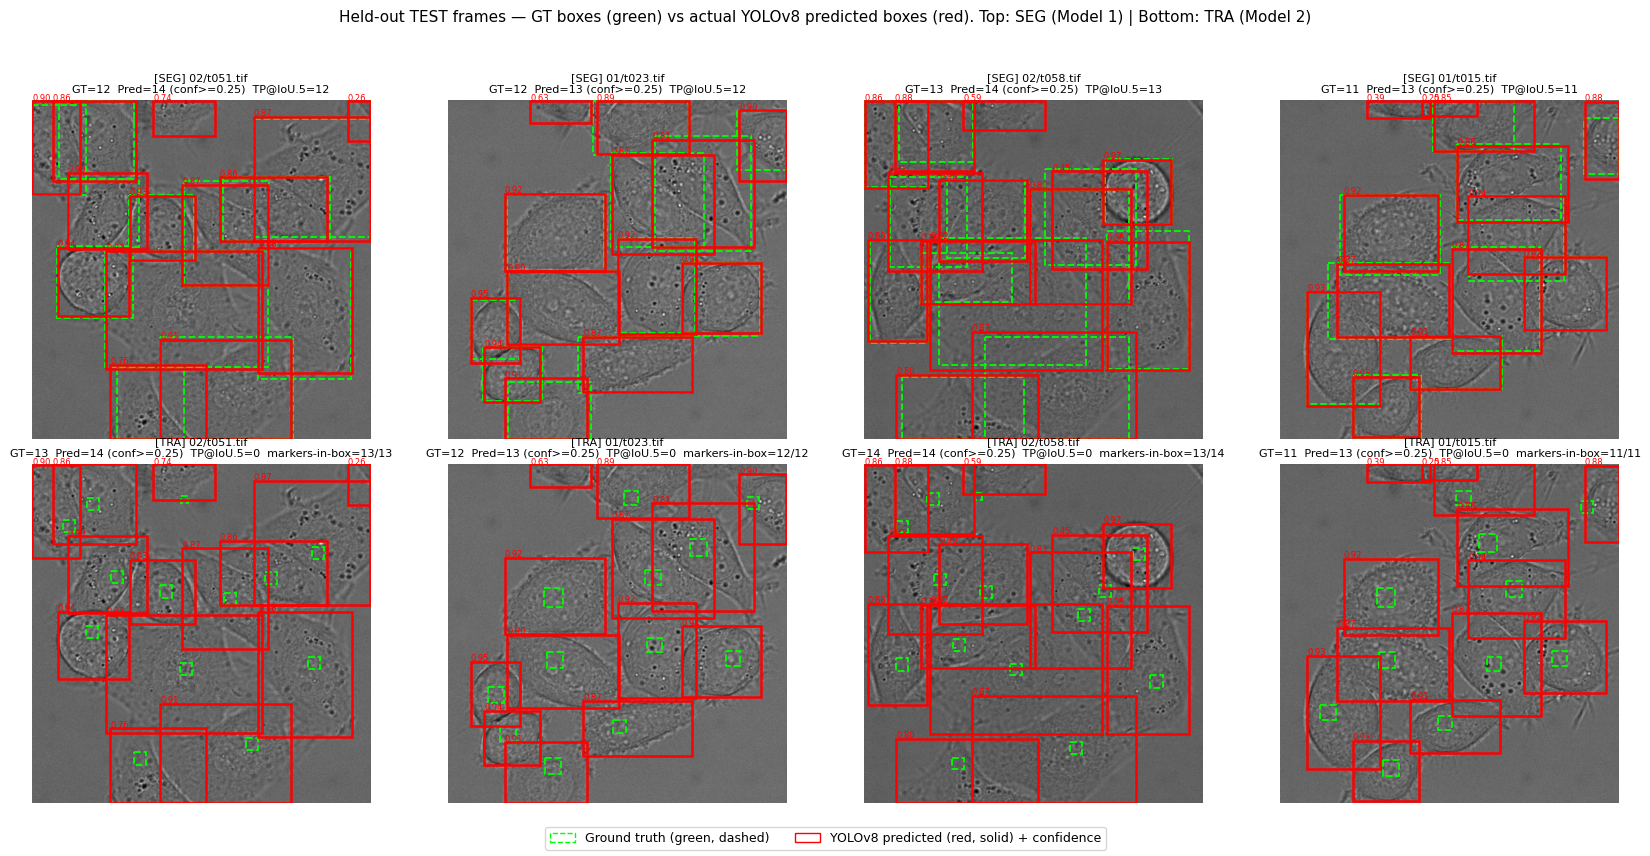

task    image  n_gt  n_pred  tp_iou50  max_score  n_raw  valid problems
 seg t051.tif    12      14        12      0.942     14   True         
 seg t023.tif    12      13        12      0.950     13   True         
 seg t058.tif    13      14        13      0.971     14   True         
 seg t015.tif    11      13        11      0.936     13   True         
 tra t051.tif    13      14         0      0.942     14   True         
 tra t023.tif    12      13         0      0.950     13   True         
 tra t058.tif    14      14         0      0.971     14   True         
 tra t015.tif    11      13         0      0.936     13   True         


In [ ]:
## ── Cell 8 : Prediction helpers + GT-vs-Predicted box visualisation — REPLACEMENT ──
## Same public API as before (predict_yolo_boxes, predict_boxes_seg, predict_boxes_tra) so Cells 8c/10/11/12/13 keep working.
## New: scores are kept, nothing is dropped silently, and the plot ASSERTS that every box was really drawn.

YOLO_CONF_SEG = 0.25   # deployed thresholds (unchanged). They are tuned on VAL only (Cell 8c); never on test.
YOLO_CONF_TRA = 0.12
YOLO_IOU      = 0.5    # NMS IoU threshold

def xyxy_to_inclusive(raw_xyxy, scores, H, W):
    """Continuous model output [x1,y1,x2,y2] (right/bottom edge EXCLUSIVE, as ultralytics/torchvision return)
    -> inclusive integer pixel boxes (same convention as bbox_from_mask). Returns (boxes, scores, n_dropped)."""
    raw = np.asarray(raw_xyxy, dtype=np.float64).reshape(-1, 4)
    sc  = np.asarray(scores,   dtype=np.float64).reshape(-1)
    order = np.argsort(-sc, kind='stable'); raw, sc = raw[order], sc[order]
    boxes, keep, dropped = [], [], 0
    for (x1, y1, x2, y2), s in zip(raw, sc):
        b = [int(np.clip(round(x1), 0, W - 1)),     int(np.clip(round(y1), 0, H - 1)),
             int(np.clip(round(x2) - 1, 0, W - 1)), int(np.clip(round(y2) - 1, 0, H - 1))]
        if b[2] > b[0] and b[3] > b[1]: boxes.append(b); keep.append(float(s))
        else:                           dropped += 1
    return boxes, np.array(keep), dropped

def predict_yolo_detailed(model, img2d, conf, imgsz, iou=YOLO_IOU):
    """Raw frame -> dict(boxes, scores, n_raw, n_dropped, raw_xyxy, raw_scores). Boxes are inclusive pixel coords."""
    H, W = img2d.shape[:2]
    res = model.predict(to_uint8_rgb(img2d), imgsz=imgsz, conf=conf, iou=iou, device=YOLO_DEVICE, verbose=False)[0]
    assert tuple(res.orig_shape) == (H, W), f'YOLO orig_shape {res.orig_shape} != image {(H, W)}'
    raw = res.boxes.xyxy.cpu().numpy(); sc = res.boxes.conf.cpu().numpy()
    boxes, scores, dropped = xyxy_to_inclusive(raw, sc, H, W)
    return dict(boxes=boxes, scores=scores, n_raw=len(raw), n_dropped=dropped, raw_xyxy=raw, raw_scores=sc, hw=(H, W))

def predict_yolo_boxes(model, img2d, conf, imgsz, iou=YOLO_IOU, max_boxes=None):
    """Raw 2D frame -> list of [x1,y1,x2,y2] (inclusive), sorted by confidence. imgsz = size used in training."""
    boxes = predict_yolo_detailed(model, img2d, conf, imgsz, iou)['boxes']
    return boxes[:max_boxes] if max_boxes is not None else boxes

# n_boxes is accepted only for backward compatibility with evaluate()/HeLaDataset; it is ignored.
def predict_boxes_seg(img2d, n_boxes=None, conf=None):
    return predict_yolo_boxes(detector_seg, img2d, conf=YOLO_CONF_SEG if conf is None else conf, imgsz=YOLO_IMGSZ_SEG)

def predict_boxes_tra(img2d, n_boxes=None, conf=None):
    if TRA_BOX_SOURCE == 'seg':          # full-cell boxes from the working SEG detector (same weights, same conf, same imgsz)
        return predict_boxes_seg(img2d, n_boxes=n_boxes, conf=conf)
    return predict_yolo_boxes(detector_tra, img2d, conf=YOLO_CONF_TRA if conf is None else conf, imgsz=YOLO_IMGSZ_TRA)

def markers_in_boxes(marker_boxes, pred_boxes):
    """How many TRA markers have their CENTRE inside at least one predicted (full-cell) box. This -- not IoU -- is the right
    box check when the GT objects are ~18 px markers and the prompts are ~150 px cell boxes (IoU is ~0 by construction)."""
    n = 0
    for g in marker_boxes:
        cx, cy = (g[0] + g[2]) / 2, (g[1] + g[3]) / 2
        n += any(b[0] <= cx <= b[2] and b[1] <= cy <= b[3] for b in pred_boxes)
    return n

def yolo_for(task):
    """(model, imgsz, deployed_conf, mask_index, predict_fn) for 'seg' / 'tra' — resolved at call time."""
    tra = ((detector_seg, YOLO_IMGSZ_SEG, YOLO_CONF_SEG, 2, predict_boxes_tra) if TRA_BOX_SOURCE == 'seg'
           else (detector_tra, YOLO_IMGSZ_TRA, YOLO_CONF_TRA, 2, predict_boxes_tra))
    return {'seg': (detector_seg, YOLO_IMGSZ_SEG, YOLO_CONF_SEG, 1, predict_boxes_seg), 'tra': tra}[task]

def box_iou_matrix(A, B):
    """IoU matrix (len(A), len(B)); same inclusive convention as box_iou() in Cell 5."""
    A = np.asarray(A, np.float64).reshape(-1, 4); B = np.asarray(B, np.float64).reshape(-1, 4)
    if len(A) == 0 or len(B) == 0: return np.zeros((len(A), len(B)))
    x1 = np.maximum(A[:, None, 0], B[None, :, 0]); y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2]); y2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1]); ab = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-8)

def greedy_tp_matrix(M, thr):
    """# one-to-one matches with value >= thr in an (n_pred x n_gt) overlap matrix (greedy, best first)."""
    used_p, used_g, tp = set(), set(), 0
    if M.size == 0: return 0
    for flat in np.argsort(-M, axis=None):
        pi, gi = divmod(int(flat), M.shape[1])
        if M[pi, gi] < thr: break
        if pi in used_p or gi in used_g: continue
        used_p.add(pi); used_g.add(gi); tp += 1
    return tp

def greedy_tp(pred, gt, thr):
    return greedy_tp_matrix(box_iou_matrix(pred, gt), thr)

# ── drawing: GT = green dashed, predicted = red solid ────────────────────────
from matplotlib.colors import to_rgba
def draw_gt_pred(ax, img, gt_boxes, pred_boxes, pred_scores=None, title='', empty_note=None, show_scores=True):
    H, W = img.shape[:2]
    ax.imshow(img, cmap='gray')
    for x1, y1, x2, y2 in gt_boxes:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.3, edgecolor='lime',
                                       facecolor='none', linestyle='--', zorder=3))
    for k, (x1, y1, x2, y2) in enumerate(pred_boxes):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.8, edgecolor='red',
                                       facecolor='none', zorder=4))
        if show_scores and pred_scores is not None and len(pred_boxes) <= 40:
            ax.text(x1, max(y1 - 2, 0), f'{pred_scores[k]:.2f}', color='red', fontsize=6, zorder=5)
    ax.set_xlim(-0.5, W - 0.5); ax.set_ylim(H - 0.5, -0.5)
    n_red   = sum(1 for p in ax.patches if to_rgba(p.get_edgecolor()) == to_rgba('red'))
    n_green = sum(1 for p in ax.patches if to_rgba(p.get_edgecolor()) == to_rgba('lime'))
    assert (n_red, n_green) == (len(pred_boxes), len(gt_boxes)), 'VISUALISATION BUG: not every box was drawn'
    if len(pred_boxes) == 0:
        ax.text(0.5, 0.5, empty_note or 'NO PREDICTED BOXES', transform=ax.transAxes, color='red', ha='center',
                va='center', fontsize=10, zorder=6, bbox=dict(facecolor='white', alpha=0.85, edgecolor='red'))
    ax.set_title(title, fontsize=8); ax.axis('off')
    return n_red, n_green

def plot_box_row(task, pairs_subset, ax_row, conf=None):
    """One row of axes: raw image + GT (green) + actual YOLO predictions (red), with counts in every title."""
    model, imgsz, dconf, mask_index, _ = yolo_for(task)
    conf = dconf if conf is None else conf
    rows = []
    for ax, entry in zip(ax_row, pairs_subset):
        img = tiff.imread(entry[0]).astype(np.float32)
        gt_boxes = [b.tolist() for _, b in get_instance_boxes(tiff.imread(entry[mask_index]).astype(np.int32))]
        det = predict_yolo_detailed(model, img, conf, imgsz)
        ok, probs = validate_boxes(det['boxes'], *img.shape[:2])
        tp  = greedy_tp(det['boxes'], gt_boxes, 0.5)
        mx  = float(det['scores'].max()) if len(det['scores']) else float('nan')
        title = (f"[{task.upper()}] {os.path.basename(os.path.dirname(entry[0]))}/{os.path.basename(entry[0])}\n"
                 f"GT={len(gt_boxes)}  Pred={len(det['boxes'])} (conf>={conf})  TP@IoU.5={tp}"
                 + (f"  markers-in-box={markers_in_boxes(gt_boxes, det['boxes'])}/{len(gt_boxes)}" if (task == 'tra' and TRA_BOX_SOURCE == 'seg') else '')
                 + ('' if ok else '  ⚠INVALID'))
        note = (f"NO PREDICTED BOXES at conf>={conf}\n(raw dets before filtering: {det['n_raw']}, dropped invalid: {det['n_dropped']})")
        draw_gt_pred(ax, img, gt_boxes, det['boxes'], det['scores'], title=title, empty_note=note)
        rows.append(dict(task=task, image=os.path.basename(entry[0]), n_gt=len(gt_boxes), n_pred=len(det['boxes']),
                         tp_iou50=tp, max_score=round(mx, 3), n_raw=det['n_raw'], valid=ok, problems='; '.join(probs)))
    return rows

N_SAMPLES = 4
legend_handles = [patches.Patch(edgecolor='lime', facecolor='none', linestyle='--', label='Ground truth (green, dashed)'),
                  patches.Patch(edgecolor='red',  facecolor='none', label='YOLOv8 predicted (red, solid) + confidence')]

fig, axes = plt.subplots(2, N_SAMPLES, figsize=(4.2 * N_SAMPLES, 8.6))
rows  = plot_box_row('seg', test_seg[:N_SAMPLES], axes[0])
rows += plot_box_row('tra', test_tra[:N_SAMPLES], axes[1])
fig.legend(handles=legend_handles, loc='lower center', ncol=2, fontsize=9)
fig.suptitle('Held-out TEST frames — GT boxes (green) vs actual YOLOv8 predicted boxes (red). Top: SEG (Model 1) | Bottom: TRA (Model 2)', fontsize=11)
plt.tight_layout(rect=[0, 0.04, 1, 0.95]); plt.show()
print(pd.DataFrame(rows).to_string(index=False))


## Cell 8a — Why might red boxes be missing? (weights / threshold / conversion / drawing)  **[NEW]**

In [ ]:
## ── Cell 8a : WHY might red boxes be missing?  Weights / threshold / conversion / drawing, told apart ──
## NEW CELL — insert after Cell 8. Run it whenever a figure shows no red boxes. It prints a verdict per detector.

def audit_weights(task):
    cfg = YOLO_CFG[task]; model, imgsz, conf, mask_index, _ = yolo_for(task)
    path = ckpt_path(cfg['ckpt']); info = inspect_yolo_ckpt(model, path)
    print(f"\n── [{task.upper()}] 1) WEIGHTS ─────────────────────────────────────────────")
    print(f"   expected file : {path}")
    print(f"   actually loaded: {info['loaded_from']}")
    print(f"   size {info['size_mb']} MB | sha {info['sha']} | saved {info['mtime']} | head task={info['task']} | classes={info['names']}")
    print(f"   trained: {info['train_model']} imgsz={info['imgsz']} epochs={info['epochs']} | stored val mAP50={info['map50']} | data={info['data']}")
    problems = []
    if os.path.abspath(info['loaded_from']) != os.path.abspath(path): problems.append('loaded file != expected file')
    if info['imgsz'] is not None and int(info['imgsz']) != imgsz:   problems.append(f"INFERENCE imgsz={imgsz} but TRAINED imgsz={info['imgsz']}")
    if info['task'] != 'detect' or list(info['names'].values()) != ['cell']: problems.append('not a 1-class detector named cell')
    if info['train_args'] and f"/{task}/" not in info['data'].replace('\\', '/'): problems.append("trained on a different task's dataset")
    if info['map50'] is not None and info['map50'] < MIN_VAL_MAP50_TO_REUSE: problems.append(f"stored val mAP50 only {info['map50']:.3f}")
    print('   ' + ('⚠️  ' + ' | '.join(problems) if problems else '✅ weights look like the right detector for this task'))
    return problems

def preprocessing_matches_training(task, entry_train):
    """Is the array we feed at inference byte-identical to the PNG the detector was trained on?"""
    stem = f"{os.path.basename(os.path.dirname(entry_train[0]))}_{os.path.splitext(os.path.basename(entry_train[0]))[0]}"
    for split in ('train', 'val'):
        p = os.path.join(YOLO_ROOT, task, 'images', split, stem + '.png')
        if os.path.exists(p):
            png = cv2.imread(p)                                   # BGR, 3 identical channels
            return bool(np.array_equal(png, to_uint8_rgb(tiff.imread(entry_train[0])))), p
    return None, None

def classify(det_lo, det_op, n_gt, conf):
    if det_lo['n_raw'] == 0:
        return 'NO_RAW_DETECTIONS', 'model emits nothing even at conf=0.001'
    if len(det_op['boxes']) == 0 and det_op['n_raw'] == 0:
        return 'BELOW_CONF', f"best raw score {det_lo['raw_scores'].max():.3f} < conf {conf}"
    if len(det_op['boxes']) == 0:
        return 'ALL_BOXES_INVALID', f"{det_op['n_dropped']} raw boxes dropped as degenerate"
    ok, probs = validate_boxes(det_op['boxes'], *det_op['hw'])
    if not ok: return 'INVALID_BOXES', '; '.join(probs)
    if probs:  return 'SUSPICIOUS_BOXES', '; '.join(probs)
    if len(det_op['boxes']) < 0.5 * n_gt: return 'TOO_FEW', f"{len(det_op['boxes'])} predicted vs {n_gt} GT"
    return 'OK', ''

def audit_predictions(task, n_each=2):
    model, imgsz, conf, mask_index, _ = yolo_for(task)
    groups = [('TRAIN', (train_seg if task == 'seg' else train_tra)[:n_each]),
              ('VAL',   (val_seg   if task == 'seg' else val_tra)[:n_each]),
              ('TEST',  (test_seg  if task == 'seg' else test_tra)[:n_each])]
    print(f"\n── [{task.upper()}] 2) PREDICTIONS  (deployed conf={conf}, imgsz={imgsz}, NMS iou={YOLO_IOU}) ──")
    rows = []
    for gname, ents in groups:
        for e in ents:
            img = tiff.imread(e[0]).astype(np.float32); H, W = img.shape
            gt  = [b.tolist() for _, b in get_instance_boxes(tiff.imread(e[mask_index]).astype(np.int32))]
            lo  = predict_yolo_detailed(model, img, 0.001, imgsz)
            op  = predict_yolo_detailed(model, img, conf,  imgsz)
            status, why = classify(lo, op, len(gt), conf)
            top = ', '.join(f'{s:.2f}' for s in op['scores'][:5])
            rows.append(dict(split=gname, image=f"{os.path.basename(os.path.dirname(e[0]))}/{os.path.basename(e[0])}", n_gt=len(gt),
                             raw_at_0_001=lo['n_raw'], pred_at_conf=len(op['boxes']),
                             max_conf=round(float(lo['raw_scores'].max()), 3) if lo['n_raw'] else None,
                             top5_conf=top, status=status, detail=why))
            if len(op['boxes']):
                b = np.array(op['boxes']); print(f"   {gname} {rows[-1]['image']}: first box (x1,y1,x2,y2)={op['boxes'][0]}  "
                                                  f"min/max x={b[:,0].min()}/{b[:,2].max()} y={b[:,1].min()}/{b[:,3].max()}  image={W}x{H}")
    df = pd.DataFrame(rows); print(df.to_string(index=False)); return df

def audit_drawing(task):
    """Draw one TEST frame into a throw-away axes and count red/green rectangles vs the numbers we meant to draw."""
    model, imgsz, conf, mask_index, _ = yolo_for(task)
    e = (test_seg if task == 'seg' else test_tra)[0]
    img = tiff.imread(e[0]).astype(np.float32)
    gt  = [b.tolist() for _, b in get_instance_boxes(tiff.imread(e[mask_index]).astype(np.int32))]
    det = predict_yolo_detailed(model, img, conf, imgsz)
    fig, ax = plt.subplots(figsize=(1, 1))
    n_red, n_green = draw_gt_pred(ax, img, gt, det['boxes'], det['scores']); plt.close(fig)
    print(f"── [{task.upper()}] 3) DRAWING: wanted red={len(det['boxes'])} green={len(gt)}  | matplotlib holds red={n_red} green={n_green}  → "
          + ('✅ drawing is faithful' if (n_red, n_green) == (len(det['boxes']), len(gt)) else '❌ drawing bug'))

def verdict(task, df, w_problems):
    tr, other = df[df.split == 'TRAIN'], df[df.split != 'TRAIN']
    print(f"\n── [{task.upper()}] VERDICT ─────────────────────────────────────────────")
    if (tr.status == 'NO_RAW_DETECTIONS').all():
        print('   ❌ WEIGHTS / PREPROCESSING / TRAINING problem: the detector emits NOTHING even on its own training frames.')
        print('      → not a threshold issue and not a plotting issue. Check section 1 (imgsz, data yaml, mAP50) and section 4 (preprocessing).')
    elif (other.status == 'NO_RAW_DETECTIONS').all():
        print('   ❌ Detector works on training frames but emits nothing on held-out frames → severe overfitting / failed generalisation.')
    elif (other.status == 'BELOW_CONF').any():
        print('   ⚠️  CONFIDENCE-THRESHOLD problem: raw detections exist but all score below the deployed conf.')
        print('      → choose a lower conf using VAL frames only (Cell 8c sweep). Never pick it on test.')
    elif (other.status.isin(['ALL_BOXES_INVALID', 'INVALID_BOXES'])).any():
        print('   ⚠️  BOX-CONVERSION problem (coordinates outside the image / x2<=x1 / normalised): see the "detail" column.')
    elif (other.status == 'SUSPICIOUS_BOXES').any():
        print('   ⚠️  Coordinates are VALID but implausible (e.g. image-sized boxes): this is a DETECTOR-QUALITY problem (undertrained / wrong weights), not a conversion bug.')
    elif (other.status == 'TOO_FEW').any():
        print('   ⚠️  Detector works but under-detects (fewer than half of GT boxes) — weak model or conf too high; see Cell 8c / 8d.')
    else:
        print('   ✅ Detections exist, are valid and are drawn. If a figure still lacks red boxes, you are looking at stale output → re-run Cells 7, 8.')
    if w_problems: print('   (weights warnings above also apply)')

for _task in (('seg', 'tra') if TRA_BOX_SOURCE == 'tra' else ('seg',)):   # no TRA detector exists when TRA_BOX_SOURCE == 'seg'
    wp  = audit_weights(_task)
    dfa = audit_predictions(_task)
    audit_drawing(_task)
    ok, p = preprocessing_matches_training(_task, (train_seg if _task == 'seg' else train_tra)[0])
    print(f"── [{_task.upper()}] 4) PREPROCESSING vs training PNG: " +
          ('✅ byte-identical' if ok else '❌ DIFFERENT' if ok is False else '(training PNGs not on disk this session — skipped; they exist only after a training run)'))
    verdict(_task, dfa, wp)



── [SEG] 1) WEIGHTS ─────────────────────────────────────────────
   expected file : /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/yolov8_seg.pt
   actually loaded: /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/yolov8_seg.pt
   size 22.5 MB | sha fe35238e13ea | saved 2026-10-16 01:55 | head task=detect | classes={0: 'cell'}
   trained: yolov8s.pt imgsz=512 epochs=50 | stored val mAP50=0.99375 | data=/content/yolo_data/seg/data.yaml
   ✅ weights look like the right detector for this task

── [SEG] 2) PREDICTIONS  (deployed conf=0.25, imgsz=512, NMS iou=0.5) ──
   TRAIN 02/t062.tif: first box (x1,y1,x2,y2)=[0, 1, 83, 134]  min/max x=0/511 y=0/511  image=512x512
   TRAIN 01/t024.tif: first box (x1,y1,x2,y2)=[358, 249, 477, 354]  min/max x=21/511 y=0/511  image=512x512
   VAL 02/t017.tif: first box (x1,y1,x2,y2)=[0, 0, 140, 105]  min/max x=0/504 y=0/511  image=512x512
   VAL 02/t066.tif: first box (x1,y1,x2,y2)=[205, 357, 329, 464]  min/max x=0/511 y=0/511  image=512x5

## Cell 8b — Diagnostic example: how an EMPTY prediction is rendered  **[REPLACED]**

The old 8b re-drew the Cell 8 grid. This shows one test frame at the deployed threshold, at conf=0.001 (every raw detection), and with a deliberately empty prediction list.


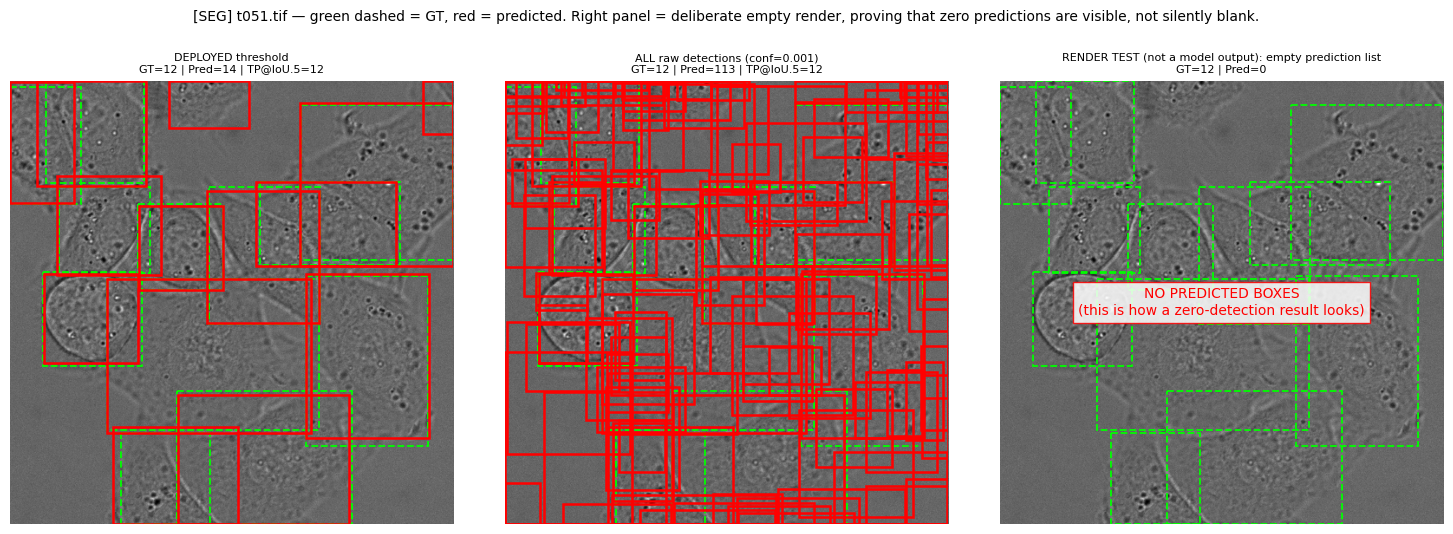

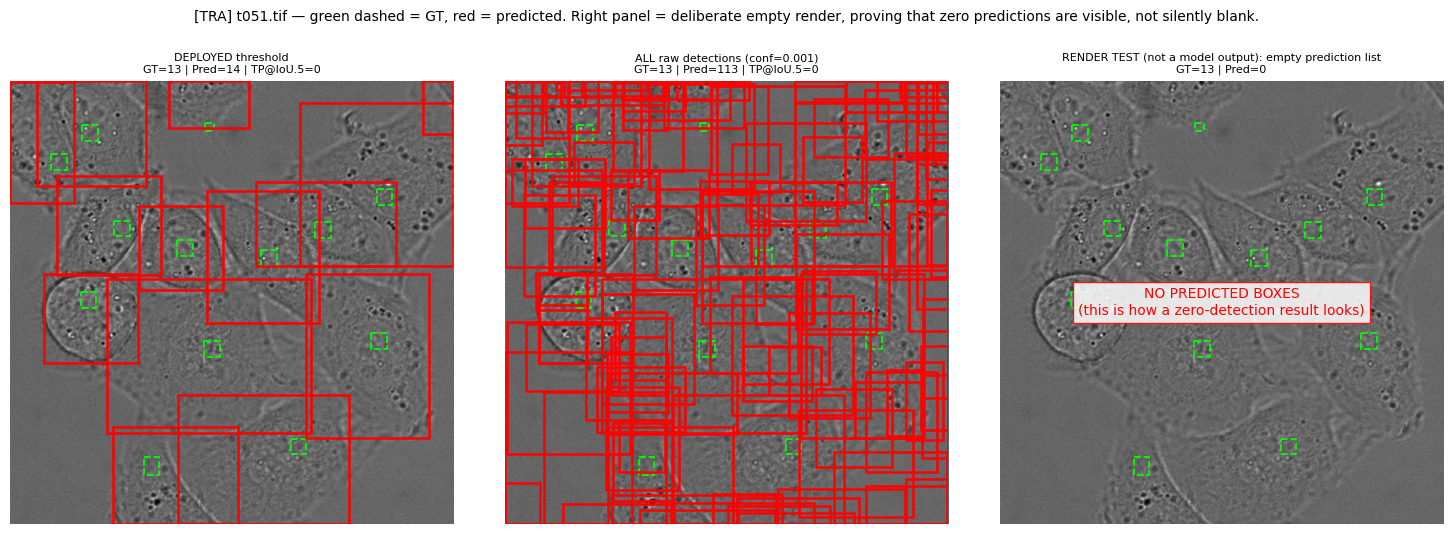

In [ ]:
## ── Cell 8b : Diagnostic example — how an EMPTY prediction is rendered — REPLACEMENT ──
## (the old Cell 8b re-drew the same grid as Cell 8). This one shows ONE test frame at two confidence levels plus an empty-list render test, so you
## can see (left) the deployed result, (middle) EVERY raw detection down to conf=0.001, (right) a deliberately empty prediction list.

def zero_prediction_example(task, entry=None):
    model, imgsz, dconf, mask_index, _ = yolo_for(task)
    entry = entry or (test_seg if task == 'seg' else test_tra)[0]
    img = tiff.imread(entry[0]).astype(np.float32)
    gt  = [b.tolist() for _, b in get_instance_boxes(tiff.imread(entry[mask_index]).astype(np.int32))]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    for ax, (c, tag) in zip(axes[:2], [(dconf, 'DEPLOYED threshold'), (0.001, 'ALL raw detections (conf=0.001)')]):
        det = predict_yolo_detailed(model, img, c, imgsz)
        tp  = greedy_tp(det['boxes'], gt, 0.5)
        draw_gt_pred(ax, img, gt, det['boxes'], det['scores'], show_scores=False,
                     title=f"{tag}\nGT={len(gt)} | Pred={len(det['boxes'])} | TP@IoU.5={tp}",
                     empty_note=f"NO PREDICTED BOXES at conf>={c}\n(raw before filtering: {det['n_raw']})")
    # deterministic: an EMPTY prediction list is passed straight to the drawing code (not a model output)
    draw_gt_pred(axes[2], img, gt, [], [], show_scores=False,
                 title=f"RENDER TEST (not a model output): empty prediction list\nGT={len(gt)} | Pred=0",
                 empty_note='NO PREDICTED BOXES\n(this is how a zero-detection result looks)')
    fig.suptitle(f"[{task.upper()}] {os.path.basename(entry[0])} — green dashed = GT, red = predicted. "
                 f"Right panel = deliberate empty render, proving that zero predictions are visible, not silently blank.", fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

zero_prediction_example('seg'); zero_prediction_example('tra')


## Cell 8c — Detector diagnostic (MANDATORY: run BEFORE any MedSAM fine-tuning)  **[v3]**

**SEG:** predicted vs ground-truth boxes (recall / precision at IoU ≥ 0.3), as before.

**TRA (default, `TRA_BOX_SOURCE='seg'`):** the prompts are full-cell boxes (~150 px) and the TRA targets are ~18 px markers, so IoU between them is ~0 by
construction and would look like total failure. The right check is **coverage**: does each TRA marker lie inside a predicted cell box
(`marker_recall`), and does each box contain a marker (`box_precision`)? `merged` counts boxes containing 2+ markers (touching cells fused into one box).

**Gate:** if coverage is below 0.80 / 0.60, Cell 12 refuses to fine-tune TRA (override with `FORCE_TRA = True`).


In [ ]:
## ── Cell 8c : Detector diagnostic (predicted vs GT boxes, recall / precision @ IoU>=0.3) ──

MATCH_IOU = 0.3          # simple, forgiving matching threshold (TRA markers are tiny)

def _match(pred, gt, thr):
    """Greedy one-to-one matching by IoU. Returns number of true positives."""
    cand = sorted(((box_iou(p, g), pi, gi) for pi, p in enumerate(pred)
                   for gi, g in enumerate(gt)), reverse=True)
    used_p, used_g, tp = set(), set(), 0
    for iou, pi, gi in cand:
        if iou < thr: break
        if pi in used_p or gi in used_g: continue
        used_p.add(pi); used_g.add(gi); tp += 1
    return tp

def _load_val(pairs, mask_index):
    cache = []
    for e in pairs:
        if e[mask_index] is None: continue
        img = tiff.imread(e[0]).astype(np.float32)
        gt  = [b.tolist() for _, b in get_instance_boxes(tiff.imread(e[mask_index]).astype(np.int32))]
        cache.append((img, gt))
    return cache

def diagnose(name, cache, pred_fn, conf, thr=MATCH_IOU, verbose=True):
    """Mean predicted vs GT boxes + box-level recall/precision on one validation set."""
    n_gt = n_pred = tp = empty = 0
    for img, gt in cache:
        pb = pred_fn(img, conf=conf)
        n_gt += len(gt); n_pred += len(pb); empty += (len(pb) == 0)
        tp   += _match(pb, gt, thr)
    res = dict(mean_gt=n_gt/len(cache), mean_pred=n_pred/len(cache), empty=empty,
               recall=tp/max(n_gt, 1), precision=tp/max(n_pred, 1))
    if verbose:
        print(f"[{name}] conf={conf:.2f} | val imgs={len(cache)} | GT boxes/img={res['mean_gt']:.1f} | "
              f"pred boxes/img={res['mean_pred']:.1f} | empty imgs={empty} | "
              f"recall@IoU{thr}={res['recall']:.2f} | precision@IoU{thr}={res['precision']:.2f}")
    return res

val_cache_seg = _load_val(val_seg, 1)
val_cache_tra = _load_val(val_tra, 2)

print('=' * 100)
seg_diag = diagnose('SEG', val_cache_seg, predict_boxes_seg, YOLO_CONF_SEG)
print('=' * 100)

TRA_MIN_MEAN_BOXES = 5
FORCE_TRA          = False     # set True to fine-tune TRA anyway
TRA_MIN_RECALL, TRA_MIN_PRECISION = 0.5, 0.3     # (only used when TRA_BOX_SOURCE == 'tra')

if TRA_BOX_SOURCE == 'tra':
    # ── old route: separate TRA detector judged by box IoU against the ~18 px markers ──────────────────────────
    tra_diag = diagnose('TRA', val_cache_tra, predict_boxes_tra, YOLO_CONF_TRA)
    print('\nTRA confidence sweep (info only; the pipeline keeps YOLO_CONF_TRA =', YOLO_CONF_TRA, ')')
    for c in [0.05, 0.12, 0.25]:
        diagnose('TRA', val_cache_tra, predict_boxes_tra, c)
    TRA_DETECTOR_OK = bool(tra_diag['mean_pred'] >= TRA_MIN_MEAN_BOXES
                           and tra_diag['recall'] >= TRA_MIN_RECALL and tra_diag['precision'] >= TRA_MIN_PRECISION)
    print('\u2705 TRA detector OK.' if TRA_DETECTOR_OK else '\u26a0\ufe0f TRA detector still broken -- do NOT fine-tune TRA.')
else:
    # ── v3 route: SEG boxes on TRA frames. IoU against 18-px markers is meaningless (it is ~0 by construction), ──
    # ── so the correct check is COVERAGE: does every TRA marker lie inside one predicted cell box? ─────────────
    def marker_coverage(cache, conf):
        n_mk = hit = n_box = box_with = multi = empty = 0
        for img, gt in cache:                                  # gt = TRA marker boxes
            pb = predict_boxes_tra(img, conf=conf)
            cen = [((g[0] + g[2]) / 2, (g[1] + g[3]) / 2) for g in gt]
            inside = [[b[0] <= cx <= b[2] and b[1] <= cy <= b[3] for (cx, cy) in cen] for b in pb]   # box x marker
            n_mk += len(cen); n_box += len(pb); empty += (len(pb) == 0)
            hit      += sum(any(inside[bi][mi] for bi in range(len(pb))) for mi in range(len(cen)))
            box_with += sum(any(row) for row in inside)
            multi    += sum(sum(row) > 1 for row in inside)
        return dict(mean_markers=n_mk / len(cache), mean_boxes=n_box / len(cache), empty=empty,
                    marker_recall=hit / max(n_mk, 1), box_precision=box_with / max(n_box, 1), boxes_with_2plus_markers=multi)
    print(f'TRA frames prompted with SEG-detector boxes (conf={YOLO_CONF_SEG}) -- marker COVERAGE on val_tra:')
    print(f'{"conf":>6} {"markers/img":>12} {"boxes/img":>10} {"empty":>6} {"marker_recall":>14} {"box_precision":>14} {"merged(2+ markers)":>19}')
    for c in sorted({0.10, 0.25, YOLO_CONF_SEG}):
        r = marker_coverage(val_cache_tra, c)
        print(f'{c:>6.2f} {r["mean_markers"]:>12.1f} {r["mean_boxes"]:>10.1f} {r["empty"]:>6d} {r["marker_recall"]:>14.2f} {r["box_precision"]:>14.2f} {r["boxes_with_2plus_markers"]:>19d}')
    tra_cov = marker_coverage(val_cache_tra, YOLO_CONF_SEG)
    TRA_MIN_MARKER_RECALL, TRA_MIN_BOX_PRECISION = 0.80, 0.60
    TRA_DETECTOR_OK = bool(tra_cov['mean_boxes'] >= TRA_MIN_MEAN_BOXES and tra_cov['marker_recall'] >= TRA_MIN_MARKER_RECALL
                           and tra_cov['box_precision'] >= TRA_MIN_BOX_PRECISION)
    print()
    if TRA_DETECTOR_OK:
        print(f"\u2705 SEG boxes cover {tra_cov['marker_recall']:.0%} of TRA markers ({tra_cov['mean_boxes']:.1f} boxes vs {tra_cov['mean_markers']:.1f} markers per frame).")
    else:
        print('\u26a0\ufe0f' * 3, 'SEG boxes do NOT cover the TRA markers well enough:',
              f"recall={tra_cov['marker_recall']:.2f} (need {TRA_MIN_MARKER_RECALL}), box_precision={tra_cov['box_precision']:.2f} (need {TRA_MIN_BOX_PRECISION}),",
              f"boxes/img={tra_cov['mean_boxes']:.1f} (need {TRA_MIN_MEAN_BOXES}).  Do NOT fine-tune TRA yet.")
if seg_diag['mean_pred'] < 0.5 * seg_diag['mean_gt']:
    print('\u26a0\ufe0f SEG detector predicts far fewer boxes than GT -- SEG should be working, check Cell 7.')


[SEG] conf=0.25 | val imgs=34 | GT boxes/img=12.6 | pred boxes/img=14.5 | empty imgs=0 | recall@IoU0.3=1.00 | precision@IoU0.3=0.86
TRA frames prompted with SEG-detector boxes (conf=0.25) -- marker COVERAGE on val_tra:
  conf  markers/img  boxes/img  empty  marker_recall  box_precision  merged(2+ markers)
  0.10         12.9       15.0      0           0.98           0.85                  70
  0.25         12.9       14.5      0           0.98           0.88                  70

✅ SEG boxes cover 98% of TRA markers (14.5 boxes vs 12.9 markers per frame).


## Cell 8d — Detector metrics on the held-out TEST set (P / R / mAP50 / mAP50-95)  **[NEW]**

Detector metrics only. MedSAM segmentation metrics are in Cell 13b.

In [ ]:
## ── Cell 8d : Detector metrics on the HELD-OUT TEST set (box P / R / mAP50 / mAP50-95) ──
## NEW CELL — insert after Cell 8c. Detector metrics ONLY; MedSAM segmentation metrics are reported separately (Cell 13b).
## Run it once at the end of detector development: do NOT change conf / weights because of what it prints.
## Two independent estimates are printed:
##   (a) 'own'  : model-agnostic COCO-style AP (101-pt interpolation, 1 class) on the same boxes/convention for ANY detector,
##                so Mask R-CNN predictions can go through the identical code (see export/load helpers below).
##   (b) 'ultra': ultralytics' own validator (P/R are the means at its max-F1 confidence).
import json

IOU_THRS = np.round(np.arange(0.5, 0.96, 0.05), 2)

def match_detections(preds, gts, thr, min_score=0.0):
    """COCO-style greedy matching in global score order. Returns (scores, is_tp) arrays of the kept detections."""
    ious = [box_iou_matrix(b, g) for (b, _), g in zip(preds, gts)]
    dets = sorted(((float(s), i, k) for i, (b, sc) in enumerate(preds) for k, s in enumerate(sc) if s >= min_score),
                  key=lambda t: -t[0])
    matched = [np.zeros(len(g), bool) for g in gts]; sc_out, tp_out = [], []
    for s, i, k in dets:
        tp = False
        if ious[i].size:
            cand = np.where(~matched[i] & (ious[i][k] >= thr - 1e-12), ious[i][k], -1.0)
            j = int(np.argmax(cand))
            if cand[j] >= 0: matched[i][j] = True; tp = True
        sc_out.append(s); tp_out.append(tp)
    return np.array(sc_out), np.array(tp_out, bool)

def ap_from_matches(is_tp, n_gt):
    if n_gt == 0: return float('nan')
    if len(is_tp) == 0: return 0.0
    ctp = np.cumsum(is_tp); cfp = np.cumsum(~is_tp)
    rec = ctp / n_gt; prec = ctp / (ctp + cfp)
    prec = np.maximum.accumulate(prec[::-1])[::-1]                      # precision envelope
    q = np.zeros(101)
    for ri, pi in enumerate(np.searchsorted(rec, np.linspace(0, 1, 101), side='left')):
        if pi < len(prec): q[ri] = prec[pi]
    return float(q.mean())

def detection_report(preds, gts, op_conf):
    """preds: per-image (boxes[N,4] inclusive px, scores[N]) collected at a LOW conf; gts: per-image boxes[M,4]."""
    n_gt = sum(len(g) for g in gts)
    aps  = [ap_from_matches(match_detections(preds, gts, t)[1], n_gt) for t in IOU_THRS]
    _, tp = match_detections(preds, gts, 0.5, min_score=op_conf)
    ntp = int(tp.sum()); npred = len(tp)
    P = ntp / max(npred, 1); R = ntp / max(n_gt, 1)
    return dict(n_img=len(gts), n_gt=n_gt, n_pred_at_conf=npred, conf=op_conf, precision=P, recall=R,
                f1=2 * P * R / max(P + R, 1e-9), AP50=aps[0], AP50_95=float(np.mean(aps)))

def best_conf_on_val(preds, gts, grid=np.round(np.arange(0.02, 0.96, 0.02), 2)):
    """Pick the confidence threshold with the best F1@IoU0.5 on a VALIDATION set (never call this with test data)."""
    best = max(((detection_report(preds, gts, c)['f1'], c) for c in grid)); return best[1], best[0]

def collect_yolo_predictions(task, pairs):
    model, imgsz, _, mask_index, _ = yolo_for(task); keys, preds, gts = [], [], []
    for e in tqdm(pairs, desc=f'yolo preds {task}', leave=False):
        if e[mask_index] is None: continue
        img = tiff.imread(e[0]).astype(np.float32)
        d = predict_yolo_detailed(model, img, 0.001, imgsz)               # low conf -> full precision/recall curve
        preds.append((np.array(d['boxes'], np.float64).reshape(-1, 4), d['scores']))
        gts.append(np.array([b.tolist() for _, b in get_instance_boxes(tiff.imread(e[mask_index]).astype(np.int32))], np.float64).reshape(-1, 4))
        keys.append(frame_key(e))
    return keys, preds, gts

def ultralytics_val(task, pairs, split):
    model, imgsz, _, mask_index, _ = yolo_for(task)
    yml = build_yolo_eval_yaml(task, pairs, mask_index, split)             # evaluation-only folders, never training ones
    m = model.val(data=yml, split=split, imgsz=imgsz, batch=8, conf=0.001, iou=YOLO_IOU, device=YOLO_DEVICE,
                  plots=False, verbose=False, workers=0)
    return dict(P=float(m.box.mp), R=float(m.box.mr), mAP50=float(m.box.map50), mAP50_95=float(m.box.map))

rows = []
_DET_TASKS = [x for x in [('seg', train_seg, val_seg, test_seg), ('tra', train_tra, val_tra, test_tra)] if x[0] == 'seg' or TRA_BOX_SOURCE == 'tra']
if TRA_BOX_SOURCE == 'seg': print('TRA has no detector of its own (TRA_BOX_SOURCE=\'seg\'): box metrics vs 18-px markers would be meaningless -> SEG only. TRA box coverage is in Cell 8c.')
for task, tr_pairs, va_pairs, te_pairs in _DET_TASKS:
    _, imgsz, dconf, mask_index, _ = yolo_for(task)
    kv, pv, gv = collect_yolo_predictions(task, va_pairs)
    c_val, f1_val = best_conf_on_val(pv, gv)
    print(f'[{task.upper()}] VAL-optimal conf (max F1@IoU.5) = {c_val:.2f} (F1={f1_val:.3f}); deployed conf = {dconf}. '
          f'(deployed value is NOT changed here — decide on VAL evidence only.)')
    for split, pairs in [('val', va_pairs), ('test', te_pairs)]:
        keys, preds, gts = collect_yolo_predictions(task, pairs) if split == 'test' else (kv, pv, gv)
        own = detection_report(preds, gts, dconf)
        try:    ul = ultralytics_val(task, pairs, split)
        except Exception as ex: ul = dict(P=np.nan, R=np.nan, mAP50=np.nan, mAP50_95=np.nan); print('   ultralytics val failed:', repr(ex)[:200])
        rows.append(dict(task=task.upper(), split=split + (' (used for ckpt/conf selection → optimistic)' if split == 'val' else ' (held-out)'),
                         n_img=own['n_img'], n_gt=own['n_gt'], n_pred=own['n_pred_at_conf'], conf=dconf,
                         P_own=own['precision'], R_own=own['recall'], AP50_own=own['AP50'], AP50_95_own=own['AP50_95'],
                         P_ultra=ul['P'], R_ultra=ul['R'], mAP50_ultra=ul['mAP50'], mAP50_95_ultra=ul['mAP50_95']))
det_table = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('\nYOLOv8 box-detection metrics (IoU thresholds 0.50:0.05:0.95; own P/R at deployed conf & IoU 0.5):')
print(det_table.round(3).to_string(index=False))


# ── Mask R-CNN: the SAME evaluator, fed with the old detector's raw outputs ────────────────────────────────
def export_detections(pairs, mask_index, predict_with_scores, out_json):
    """Run this in the MASK R-CNN notebook. predict_with_scores(img2d) -> (boxes[N,4] float xyxy in ORIGINAL pixel coords,
    scores[N]) at a LOW score threshold (e.g. 0.001-0.05). Needs frame_key() from Cell 3b."""
    out = {}
    for e in pairs:
        if e[mask_index] is None: continue
        b, s = predict_with_scores(tiff.imread(e[0]).astype(np.float32))
        out[frame_key(e)] = dict(boxes=np.asarray(b, float).reshape(-1, 4).tolist(), scores=np.asarray(s, float).reshape(-1).tolist())
    json.dump(out, open(out_json, 'w')); print('wrote', out_json, len(out), 'frames')

def load_external_detections(json_path, pairs, mask_index, already_inclusive=False):
    """Load another detector's boxes for exactly the frames in `pairs`; apply the SAME box conversion as YOLO."""
    d = json.load(open(json_path)); keys, preds, gts = [], [], []
    miss = [frame_key(e) for e in pairs if e[mask_index] is not None and frame_key(e) not in d]
    if miss: raise ValueError(f'{json_path} lacks {len(miss)} required frames, e.g. {miss[:3]} -> not the same test set')
    for e in pairs:
        if e[mask_index] is None: continue
        H, W = tiff.imread(e[0]).shape[:2]; r = d[frame_key(e)]
        b, s = np.array(r['boxes'], float).reshape(-1, 4), np.array(r['scores'], float)
        if already_inclusive: order = np.argsort(-s); b, s = b[order], s[order]
        else:                 b, s, _ = xyxy_to_inclusive(b, s, H, W); b = np.array(b, float).reshape(-1, 4)
        preds.append((b, s)); keys.append(frame_key(e))
        gts.append(np.array([x.tolist() for _, x in get_instance_boxes(tiff.imread(e[mask_index]).astype(np.int32))], float).reshape(-1, 4))
    return keys, preds, gts

MASKRCNN_JSON = {'seg': ckpt_path('maskrcnn_test_detections_seg.json'), 'tra': ckpt_path('maskrcnn_test_detections_tra.json')}
for task, te_pairs in [x for x in [('seg', test_seg), ('tra', test_tra)] if x[0] == 'seg' or TRA_BOX_SOURCE == 'tra']:
    if os.path.exists(MASKRCNN_JSON[task]):
        _, _, dconf, mask_index, _ = yolo_for(task)
        _, pm, gm = load_external_detections(MASKRCNN_JSON[task], te_pairs, mask_index)
        _, py, gy = collect_yolo_predictions(task, te_pairs)
        print(f'\n[{task.upper()}] SAME test frames, SAME GT, SAME evaluator:')
        print(pd.DataFrame([dict(detector='YOLOv8', **detection_report(py, gy, dconf)),
                            dict(detector='Mask R-CNN (conf = YOLO conf; re-pick on its VAL set for a fair operating point)', **detection_report(pm, gm, dconf))]).round(3).to_string(index=False))
    else:
        print(f'\n[{task.upper()}] No {os.path.basename(MASKRCNN_JSON[task])} on Drive yet -> Mask R-CNN detector comparison skipped '
              f'(export it with export_detections() from the Mask R-CNN notebook).')


TRA has no detector of its own (TRA_BOX_SOURCE='seg'): box metrics vs 18-px markers would be meaningless -> SEG only. TRA box coverage is in Cell 8c.


yolo preds seg:   0%|          | 0/34 [00:00<?, ?it/s]

[SEG] VAL-optimal conf (max F1@IoU.5) = 0.74 (F1=0.984); deployed conf = 0.25. (deployed value is NOT changed here — decide on VAL evidence only.)
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3369.8±782.7 MB/s, size: 486.4 KB)
val: Scanning /content/yolo_data/seg/labels/val... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 993.7it/s 0.0s
val: New cache created: /content/yolo_data/seg/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.5it/s 0.8s
                   all         34        427       0.98      0.979      0.994        0.8
Speed: 0.3ms preprocess, 11.2ms inference, 0.0ms loss, 0.9ms postprocess per image


yolo preds seg:   0%|          | 0/34 [00:00<?, ?it/s]

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4729.4±759.1 MB/s, size: 483.7 KB)
val: Scanning /content/yolo_data/seg/labels/test... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 923.5it/s 0.0s
val: New cache created: /content/yolo_data/seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.3it/s 0.7s
                   all         34        423      0.975      0.981      0.985      0.791
Speed: 0.3ms preprocess, 9.6ms inference, 0.0ms loss, 0.9ms postprocess per image

YOLOv8 box-detection metrics (IoU thresholds 0.50:0.05:0.95; own P/R at deployed conf & IoU 0.5):
task                                           split  n_img  n_gt  n_pred  conf  P_own  R_own  AP50_own  AP50_95_own  P_ultra  R_ultra  mAP50_ultra  mAP50_95_ult

## Cell 9 — Inspect one test image per task

In [ ]:
## ── Cell 9 : Inspect test images ────────────────────────────────────────
def inspect_test_image(entry, mask_index, task_label):
    img_p  = entry[0]
    mask_p = entry[mask_index]
    gt     = tiff.imread(mask_p).astype(np.int32)
    H, W   = gt.shape
    ids    = np.unique(gt); ids = ids[ids != 0]
    print(f'\n[{task_label}]  image={os.path.basename(img_p)}  size=({W},{H})  objects={len(ids)}')
    for oid in ids:
        b = bbox_from_mask((gt == oid).astype(np.uint8))
        if b is None: continue
        x1,y1,x2,y2 = b
        print(f'  ID={oid}  box={b}  W={round((x2-x1)/W*100,1)}%  H={round((y2-y1)/H*100,1)}%')

inspect_test_image(test_seg[0], mask_index=1, task_label='SEG')
inspect_test_image(test_tra[0], mask_index=2, task_label='TRA')


[SEG]  image=t051.tif  size=(512,512)  objects=12
  ID=2  box=[56, 122, 161, 222]  W=20.5%  H=19.5%
  ID=4  box=[147, 142, 245, 241]  W=19.1%  H=19.3%
  ID=5  box=[38, 220, 152, 329]  W=22.3%  H=21.3%
  ID=9  box=[111, 228, 356, 403]  W=47.9%  H=34.2%
  ID=16  box=[288, 116, 450, 212]  W=31.6%  H=18.8%
  ID=17  box=[229, 122, 358, 281]  W=25.2%  H=31.1%
  ID=18  box=[336, 28, 511, 206]  W=34.2%  H=34.8%
  ID=22  box=[342, 225, 482, 421]  W=27.3%  H=38.3%
  ID=23  box=[193, 358, 395, 511]  W=39.5%  H=29.9%
  ID=26  box=[128, 406, 230, 511]  W=19.9%  H=20.5%
  ID=44  box=[41, 0, 154, 118]  W=22.1%  H=23.0%
  ID=45  box=[0, 7, 81, 142]  W=15.8%  H=26.4%

[TRA]  image=t051.tif  size=(512,512)  objects=13
  ID=2  box=[120, 161, 138, 179]  W=3.5%  H=3.5%
  ID=4  box=[193, 183, 211, 202]  W=3.5%  H=3.7%
  ID=5  box=[81, 244, 99, 262]  W=3.5%  H=3.5%
  ID=9  box=[224, 300, 242, 318]  W=3.5%  H=3.5%
  ID=16  box=[352, 163, 370, 181]  W=3.5%  H=3.5%
  ID=17  box=[290, 195, 308, 213]  W=3.5%  H=

## Cell 10 — Baseline evaluation (pretrained MedSAM, no fine-tuning)

In [ ]:
## ── Cell 10 : Baseline evaluation ───────────────────────────────────────
import inspect

def evaluate(model, dataset, predict_fn=None, mask_index=1, verbose=True):
    """
    predict_fn=None  → use perfect GT boxes (upper-bound baseline)
    predict_fn=fn    → use YOLOv8 predicted boxes (realistic scenario)
    mask_index       → 1 for SEG, 2 for TRA
    """
    rows = []; n_box_list = []
    for entry in tqdm(dataset, desc='eval'):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        if mask_p is None: continue

        img     = tiff.imread(img_p)
        gt_full = tiff.imread(mask_p).astype(np.int32)
        H, W    = gt_full.shape
        gt      = (gt_full > 0).astype(np.uint8)

        if predict_fn is not None:
            # Safely handle prediction parameters dynamically for YOLOv8
            sig = inspect.signature(predict_fn)
            if 'n_boxes' in sig.parameters:
                pred_boxes = predict_fn(img, n_boxes=5)
            else:
                pred_boxes = predict_fn(img)
        else:
            ids = np.unique(gt_full); ids = ids[ids != 0]
            pred_boxes = [b for b in
                          [bbox_from_mask((gt_full == oid).astype(np.uint8)) for oid in ids]
                          if b is not None]
        n_box_list.append(len(pred_boxes))
        if not pred_boxes:
            # detector found nothing: this is a real failure (Dice 0), NOT an image to skip.
            # (The old `continue` silently dropped these, and if ALL images were empty the
            #  function returned 0.000 with no hint that the detector produced no boxes.)
            rows.append({'image': os.path.basename(img_p), 'dice': 0.0, 'iou': 0.0,
                         'prec': 0.0, 'rec': 0.0})
            continue

        final = np.zeros((H, W), dtype=np.uint8)
        for box in pred_boxes:
            pm = medsam_predict(model, img, box)
            if pm.shape != (H, W):
                pm = cv2.resize(pm, (W, H), interpolation=cv2.INTER_NEAREST)
            final = np.maximum(final, (pm > 0.5).astype(np.uint8))

        d, i, p, r = metrics(final, gt)
        rows.append({'image': os.path.basename(img_p),
                     'dice': round(d,3), 'iou': round(i,3),
                     'prec': round(p,3), 'rec': round(r,3)})

    res = pd.DataFrame(rows)
    if predict_fn is not None and n_box_list:
        print(f'  [eval] mean predicted boxes/img = {np.mean(n_box_list):.1f} | '
              f'images with 0 boxes = {sum(n == 0 for n in n_box_list)}/{len(n_box_list)}')
    if verbose and len(res):
        print(res.to_string(index=False))
        print(f'\nMean Dice: {res.dice.mean():.3f} ± {res.dice.std():.3f}'
              f' | Mean IoU: {res.iou.mean():.3f}')
    return (res.dice.mean(), res.iou.mean(),
            res.prec.mean(), res.rec.mean()) if len(res) else (0,0,0,0)


# ── SEG baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — SEG GT boxes (baseline) ===')
base_d_seg, base_i_seg, _, _ = evaluate(medsam, test_seg,
                                         predict_fn=None, mask_index=1)

# ── TRA baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — TRA GT boxes (baseline) ===')
base_d_tra, base_i_tra, _, _ = evaluate(medsam, test_tra,
                                         predict_fn=None, mask_index=2)


=== Pretrained MedSAM — SEG GT boxes (baseline) ===


eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.908 0.831 0.931 0.886
t023.tif 0.901 0.820 0.956 0.853
t058.tif 0.897 0.812 0.918 0.876
t015.tif 0.905 0.826 0.942 0.870
t060.tif 0.894 0.808 0.910 0.879
t025.tif 0.933 0.875 0.969 0.899
t053.tif 0.901 0.819 0.922 0.880
t031.tif 0.897 0.814 0.975 0.831
t016.tif 0.912 0.839 0.941 0.885
t044.tif 0.923 0.856 0.941 0.905
t072.tif 0.898 0.816 0.938 0.862
t034.tif 0.901 0.820 0.956 0.851
t030.tif 0.899 0.817 0.953 0.851
t058.tif 0.899 0.817 0.905 0.894
t035.tif 0.910 0.834 0.956 0.867
t077.tif 0.913 0.839 0.918 0.907
t049.tif 0.906 0.827 0.907 0.904
t006.tif 0.920 0.852 0.953 0.890
t018.tif 0.912 0.837 0.960 0.868
t055.tif 0.928 0.866 0.953 0.905
t071.tif 0.910 0.835 0.932 0.889
t041.tif 0.905 0.827 0.941 0.872
t026.tif 0.913 0.840 0.941 0.887
t022.tif 0.906 0.828 0.956 0.861
t019.tif 0.887 0.797 0.936 0.843
t064.tif 0.911 0.836 0.930 0.892
t047.tif 0.901 0.821 0.914 0.889
t029.tif 0.935 0.878 0.944 0.926
t056.tif 0.911 0.837 0.939 0.885
t014.tif 0

eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.593 0.421 0.942 0.433
t023.tif 0.526 0.357 0.985 0.359
t058.tif 0.530 0.360 0.952 0.367
t015.tif 0.571 0.400 0.968 0.405
t060.tif 0.596 0.425 0.970 0.430
t025.tif 0.449 0.289 0.937 0.295
t053.tif 0.616 0.445 0.938 0.458
t031.tif 0.532 0.363 0.958 0.369
t016.tif 0.449 0.290 0.937 0.296
t044.tif 0.557 0.386 0.985 0.388
t072.tif 0.637 0.468 0.925 0.486
t034.tif 0.487 0.322 0.951 0.327
t030.tif 0.556 0.385 0.963 0.391
t058.tif 0.545 0.375 0.976 0.379
t035.tif 0.582 0.410 0.962 0.417
t077.tif 0.541 0.371 0.945 0.379
t049.tif 0.524 0.355 0.977 0.358
t006.tif 0.422 0.267 0.958 0.270
t018.tif 0.551 0.380 0.933 0.391
t055.tif 0.623 0.453 0.916 0.472
t071.tif 0.532 0.363 0.949 0.370
t041.tif 0.608 0.437 0.978 0.442
t026.tif 0.462 0.300 0.869 0.315
t022.tif 0.477 0.313 0.991 0.314
t019.tif 0.551 0.380 0.974 0.384
t064.tif 0.566 0.395 0.964 0.401
t047.tif 0.550 0.380 0.975 0.383
t029.tif 0.506 0.339 0.894 0.353
t056.tif 0.601 0.430 0.972 0.435
t014.tif 0

## Cell 11 — Dataset class & fine-tune function

In [ ]:
## ── Cell 11 : Dataset & fine-tune ───────────────────────────────────────
def collate(batch): return batch[0]   # batch_size = 1

class HeLaDataset(Dataset):
    def __init__(self, pairs, predict_fn=None, mask_index=1):
        """
        predict_fn=None  → GT boxes  (Exp B)
        predict_fn=fn    → YOLOv8 boxes (Exp A)
        mask_index       → 1 = SEG, 2 = TRA
        """
        self.pairs      = pairs
        self.predict_fn = predict_fn
        self.mask_index = mask_index
        self._box_cache = {}      # detector boxes are deterministic -> compute once per image
        self.fallback_idx = set() # images where the detector returned nothing -> full-image box used

    def __len__(self): return len(self.pairs)

    def __getitem__(self, i):
        entry  = self.pairs[i]
        img_p  = entry[0]
        mask_p = entry[self.mask_index]

        img = tiff.imread(img_p)
        H, W = img.shape

        if mask_p is None:                              # fallback: black mask
            gt    = np.zeros((H, W), dtype=np.uint8)
            boxes = np.array([[0, 0, W-1, H-1]], dtype=np.float32)
        else:
            gt_full = tiff.imread(mask_p).astype(np.int32)
            gt      = (gt_full > 0).astype(np.uint8)
            if self.predict_fn is not None:
                if i not in self._box_cache:
                    self._box_cache[i] = self.predict_fn(img, n_boxes=5)
                boxes = self._box_cache[i]
            else:
                ids   = np.unique(gt_full); ids = ids[ids != 0]
                boxes = [b for b in
                         [bbox_from_mask((gt_full==oid).astype(np.uint8)) for oid in ids]
                         if b is not None]
            if not boxes:
                self.fallback_idx.add(i)
                boxes = [[0, 0, W-1, H-1]]

        rgb   = transform.apply_image(preprocess_image(img).astype(np.uint8))
        boxes = transform.apply_boxes(np.array(boxes, dtype=np.float32), (H, W))
        return (
            torch.as_tensor(rgb).permute(2, 0, 1).float(),
            torch.tensor(gt).unsqueeze(0).float(),
            torch.tensor(boxes).float(),
            (H, W)
        )


dice_loss = DiceLoss(sigmoid=True)
bce       = torch.nn.BCEWithLogitsLoss()
scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


def forward_logits(model, img_t, boxes, hw):
    H, W   = hw
    img_t  = img_t.to(DEVICE)
    boxes  = boxes.to(DEVICE)
    in_t   = model.preprocess(img_t.unsqueeze(0))
    with torch.no_grad():
        emb = model.image_encoder(in_t)
    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=boxes, masks=None)
    low_res, _ = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    logits = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    return logits.amax(dim=0, keepdim=True)


def fine_tune(model, train_dl, val_dl, epochs=20, lr=1e-4,
              ckpt_name='model.pth', tag='FT', mask_index=1):
    for p in model.image_encoder.parameters():  p.requires_grad = False
    for p in model.prompt_encoder.parameters(): p.requires_grad = False
    for p in model.mask_decoder.parameters():   p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    best_dice = -1

    for ep in range(epochs):
        model.train(); total_loss = 0
        for img_t, gt, boxes, hw in tqdm(train_dl, desc=f'{tag} ep{ep}'):
            gt = gt.unsqueeze(0).to(DEVICE)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
                logits = forward_logits(model, img_t, boxes, hw)
                loss   = dice_loss(logits, gt) + bce(logits, gt)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            total_loss += loss.item()
        scheduler.step()

        model.eval(); vd = vi = n = 0
        with torch.no_grad():
            for img_t, gt, boxes, hw in val_dl:
                logits = forward_logits(model, img_t, boxes, hw)
                pred   = (torch.sigmoid(logits)[0,0].cpu().numpy() > 0.5).astype(np.uint8)
                d, i, _, _ = metrics(pred, gt[0].numpy())
                vd += d; vi += i; n += 1
        vd /= n; vi /= n
        print(f'{tag} ep{ep}: loss={total_loss/len(train_dl):.4f} | val_dice={vd:.4f}')
        if vd > best_dice:
            best_dice = vd
            torch.save(model.state_dict(), ckpt_name)
            print('  ✅ saved best model')

print('Dataset class and fine_tune() ready.')

Dataset class and fine_tune() ready.


/tmp/ipykernel_721/2729592025.py:58: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


In [ ]:
## ── Cell 12 : Fine-tune -- 2 experiments (Exp A & Exp B) ──────────────────
## Checkpoints are saved to CKPT_DIR (Google Drive, set up in Cell 1b) so
## they survive a runtime disconnect. Per-experiment epoch budget instead of
## one flat number: SEG tasks (and A-TRA) converge fast, but B-TRA (YOLOv8
## boxes, TRA masks) was slow to converge in the original Mask R-CNN run,
## so it gets more epochs than the others.
## v3: Exp B-TRA is fine-tuned on the SEG detector's full-cell boxes (TRA_BOX_SOURCE='seg') -> checkpoint CKPT_B_TRA (v3 name).
## Exp A-TRA (GT *marker* boxes) is detector-independent; it is kept as a reference, but it learned small-box -> marker, so with
## full-cell prompts it is EXPECTED to score low. Exp B-TRA is the model trained for full-cell prompt -> marker.
## NOTE: SEG checkpoints are unchanged and reused.
## TRA checkpoints use *_v2.pth names. The stale B-TRA checkpoint (fine-tuned on the broken detector's
## boxes) is deleted in Cell 7, so Exp B-TRA is re-trained on the NEW detector's boxes.
## Exp A-TRA (GT boxes) does not depend on the detector, so its checkpoint is reused if it exists.

FT_EPOCHS = {
    'A-SEG': 5,
    'A-TRA': 5,
    'B-SEG': 5,
    'B-TRA': 12,   # slow to converge -- worth the extra time
}

def get_or_finetune(train_pairs, val_pairs, predict_fn, mask_index, ckpt_name, tag):
    path = ckpt_path(ckpt_name)   # routed through Drive-backed CKPT_DIR (Cell 1b)
    epochs = FT_EPOCHS[tag]

    if os.path.exists(path):
        print(f'✅ Found {path} -- loading (skipping fine-tune).')
        model = load_medsam()
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        model.to(DEVICE); model.eval()
        return model

    print(f'⏳ No checkpoint for {tag} -- fine-tuning {epochs} epochs...')
    model = load_medsam()
    if DEVICE == 'cuda': torch.cuda.empty_cache()

    dl_train = DataLoader(HeLaDataset(train_pairs, predict_fn=predict_fn, mask_index=mask_index),
                           batch_size=1, shuffle=True, collate_fn=collate, num_workers=0,
                           pin_memory=(DEVICE=='cuda'))
    dl_val   = DataLoader(HeLaDataset(val_pairs,   predict_fn=predict_fn, mask_index=mask_index),
                           batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                           pin_memory=(DEVICE=='cuda'))

    fine_tune(model, dl_train, dl_val, epochs=epochs, lr=1e-4, ckpt_name=path, tag=tag)
    if predict_fn is not None:   # how often did the detector return nothing (-> full-image box fallback)?
        print(f'  [{tag}] detector-empty images -> full-image box fallback: '
              f'train={len(dl_train.dataset.fallback_idx)}/{len(dl_train.dataset)}, '
              f'val={len(dl_val.dataset.fallback_idx)}/{len(dl_val.dataset)}')
    model.load_state_dict(torch.load(path, map_location=DEVICE))  # reload best-val checkpoint
    model.to(DEVICE); model.eval()
    return model


# =========================================================================
# ─── SEG experiments (unchanged -- detector works, mAP50 = 0.994) ────
# =========================================================================
print('\n====== Exp A-SEG : GT boxes, SEG masks ======')
medsam_expA_seg = get_or_finetune(train_seg, val_seg, predict_fn=None, mask_index=1,
                                   ckpt_name='medsam_seg_gtbox.pth', tag='A-SEG')

print('\n====== Exp B-SEG : YOLOv8 boxes, SEG masks ======')
medsam_expB_seg = get_or_finetune(train_seg, val_seg, predict_fn=predict_boxes_seg, mask_index=1,
                                   ckpt_name='medsam_seg_yolo_predbox.pth', tag='B-SEG')

# =========================================================================
# ─── TRA experiments -- only after the detector passes Cell 8c ───────
# =========================================================================
if not TRA_DETECTOR_OK and not FORCE_TRA:
    raise RuntimeError(f'TRA detector still predicts < {TRA_MIN_MEAN_BOXES} boxes/img (see Cell 8c WARNING). '
                       'Fix the detector first, or set FORCE_TRA = True to fine-tune anyway.')

print('\n====== Exp A-TRA : GT boxes, TRA masks ======')
medsam_expA_tra = get_or_finetune(train_tra, val_tra, predict_fn=None, mask_index=2,
                                   ckpt_name='medsam_tra_gtbox_v2.pth', tag='A-TRA')

print(f"\n====== Exp B-TRA : {'SEG-detector (full-cell)' if TRA_BOX_SOURCE == 'seg' else 'TRA-detector'} boxes -> TRA marker masks ======")
medsam_expB_tra = get_or_finetune(train_tra, val_tra, predict_fn=predict_boxes_tra, mask_index=2,
                                   ckpt_name=CKPT_B_TRA, tag='B-TRA')



====== Exp A-SEG : GT boxes, SEG masks ======
✅ Found /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/medsam_seg_gtbox.pth -- loading (skipping fine-tune).
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0

====== Exp B-SEG : YOLOv8 boxes, SEG masks ======
✅ Found /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/medsam_seg_yolo_predbox.pth -- loading (skipping fine-tune).
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0

====== Exp A-TRA : GT boxes, TRA masks ======
⏳ No checkpoint for A-TRA -- fine-tuning 5 epochs...
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0


A-TRA ep0:   0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_721/2729592025.py:96: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


A-TRA ep0: loss=0.1105 | val_dice=0.9520
  ✅ saved best model


A-TRA ep1:   0%|          | 0/100 [00:00<?, ?it/s]

A-TRA ep1: loss=0.0516 | val_dice=0.9569
  ✅ saved best model


... (26 outputs left out)

B-TRA ep10:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep10: loss=0.3997 | val_dice=0.5497


B-TRA ep11:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep11: loss=0.3942 | val_dice=0.5503
  [B-TRA] detector-empty images -> full-image box fallback: train=0/100, val=0/34


In [ ]:
import os
files = ['medsam_seg_yolo_predbox.pth', 'medsam_seg_gtbox.pth', CKPT_B_TRA, 'medsam_tra_gtbox_v2.pth', 'yolov8_seg.pt'] \
        + (['yolov8m_tra_v2.pt'] if TRA_BOX_SOURCE == 'tra' else [])
for f in files:
    print(f, '→', 'FOUND ✅' if os.path.exists(ckpt_path(f)) else 'MISSING ❌')


medsam_seg_yolo_predbox.pth → FOUND ✅
medsam_seg_gtbox.pth → FOUND ✅
medsam_tra_segboxes_v3.pth → FOUND ✅
medsam_tra_gtbox_v2.pth → FOUND ✅
yolov8_seg.pt → FOUND ✅


## Cell 12b — Checkpoint audit (read-only)  **[NEW]**

In [ ]:
## ── Cell 12b : Checkpoint audit (read-only) — which file is which, and can it be trusted? ──────────────────
## NEW CELL — insert after Cell 12 (and again after any re-run of Cells 7/12). Deletes and changes nothing.
import time
def _row(name, kind, depends_on=None, note=''):
    p = ckpt_path(name)
    if not os.path.exists(p): return dict(file=name, kind=kind, exists=False, note='MISSING')
    r = dict(file=name, kind=kind, exists=True, size_mb=round(os.path.getsize(p) / 1e6, 1),
             saved=time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime(p))),
             sha=_sha(p), meta=os.path.exists(p + '.meta.json'), note=note)
    if depends_on and os.path.exists(ckpt_path(depends_on)):
        newer = os.path.getmtime(p) >= os.path.getmtime(ckpt_path(depends_on))
        r['newer_than_its_detector'] = newer
        if not newer: r['note'] = '❌ OLDER than the detector it should have been fine-tuned on → STALE, delete/archive it and re-run Cell 12'
    return r
audit = [_row('yolov8_seg.pt', 'YOLO detector (SEG)'), *([_row('yolov8m_tra_v2.pt', 'YOLO detector (TRA)')] if TRA_BOX_SOURCE == 'tra' else []),
         _row('medsam_seg_gtbox.pth', 'MedSAM Exp A (GT boxes)', note='legacy file from the Mask R-CNN project: valid only if that run used the SAME split (see split_manifest.json)'),
         _row('medsam_tra_gtbox_v2.pth', 'MedSAM Exp A (GT boxes)'),
         _row('medsam_seg_yolo_predbox.pth', 'MedSAM Exp B (YOLO boxes)', depends_on='yolov8_seg.pt'),
         _row(CKPT_B_TRA, 'MedSAM Exp B (YOLO boxes)', depends_on=('yolov8_seg.pt' if TRA_BOX_SOURCE == 'seg' else 'yolov8m_tra_v2.pt'))]
print(pd.DataFrame(audit).fillna('').to_string(index=False))
others = sorted(f for f in os.listdir(CKPT_DIR) if f not in {a['file'] for a in audit} and not f.endswith('.json') and not f.startswith('_'))
print('\nOther files in CKPT_DIR (NOT loaded by this notebook):', others)
print('  - detector_seg.pth / detector_tra.pth / medsam_*_predbox.pth belong to the Mask R-CNN experiment; this notebook never opens them.')


                       file                      kind  exists  size_mb            saved          sha  meta                                                                                                          note newer_than_its_detector
              yolov8_seg.pt       YOLO detector (SEG)    True     22.5 2026-10-16 01:55 fe35238e13ea False                                                                                                                                      
       medsam_seg_gtbox.pth   MedSAM Exp A (GT boxes)    True    375.1 2026-07-10 06:03 bf6da3fd72bb False legacy file from the Mask R-CNN project: valid only if that run used the SAME split (see split_manifest.json)                        
    medsam_tra_gtbox_v2.pth   MedSAM Exp A (GT boxes)    True    375.1 2026-10-19 12:09 48d41999108d False                                                                                                                                      
medsam_seg_yolo_predbox.pth MedSAM E

## Cell 13 — Final evaluation & comparison table

In [ ]:
## ── Cell 13 : Load checkpoints & test Exp A and Exp B ──────

# ═══════════════════════════════════════════════════════════════
# Exp A : trained on GT boxes / tested with YOLOv8 boxes
# ═══════════════════════════════════════════════════════════════
medsam_expA_seg = load_medsam()
medsam_expA_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_gtbox.pth'), map_location=DEVICE))
medsam_expA_seg.to(DEVICE); medsam_expA_seg.eval()

medsam_expA_tra = load_medsam()
medsam_expA_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_gtbox_v2.pth'), map_location=DEVICE))
medsam_expA_tra.to(DEVICE); medsam_expA_tra.eval()

print('Evaluating — SEG task (Exp A: train GT / test YOLOv8) ...')
expA_seg_d, expA_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (Exp A: train GT / test YOLOv8) ...')
expA_tra_d, expA_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Exp B : trained on YOLOv8 boxes / tested with YOLOv8 boxes
# ═══════════════════════════════════════════════════════════════
medsam_expB_seg = load_medsam()
medsam_expB_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_yolo_predbox.pth'), map_location=DEVICE))
medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

medsam_expB_tra = load_medsam()
medsam_expB_tra.load_state_dict(torch.load(ckpt_path(CKPT_B_TRA), map_location=DEVICE))
medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

print('Evaluating — SEG task (Exp B: train YOLOv8 / test YOLOv8) ...')
expB_seg_d, expB_seg_i, _, _ = evaluate(medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (Exp B: train YOLOv8 / test YOLOv8) ...')
expB_tra_d, expB_tra_i, _, _ = evaluate(medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Combined summary table
# ═══════════════════════════════════════════════════════════════
cmp_all = pd.DataFrame({
    'Task':  ['SEG', 'TRA', 'SEG', 'TRA'],
    'Exp': ['A (GT train, YOLOv8 test)',
            'A (GT train, YOLOv8 test)',
            'B (YOLOv8 train, YOLOv8 test)',
            'B (YOLOv8 train, YOLOv8 test)'],
    'Dice':  [round(expA_seg_d,3), round(expA_tra_d,3), round(expB_seg_d,3), round(expB_tra_d,3)],
    'IoU':   [round(expA_seg_i,3), round(expA_tra_i,3), round(expB_seg_i,3), round(expB_tra_i,3)],
})

print('\n=== Exp A vs Exp B Comparison (all tested on YOLOv8 boxes) ===')
print(cmp_all.to_string(index=False))
print()
print(f'Exp A-SEG (GT train → YOLOv8 test): Dice={expA_seg_d:.3f}  IoU={expA_seg_i:.3f}')
print(f'Exp A-TRA (GT train → YOLOv8 test): Dice={expA_tra_d:.3f}  IoU={expA_tra_i:.3f}')
print(f'Exp B-SEG (YOLOv8 train → test):    Dice={expB_seg_d:.3f}  IoU={expB_seg_i:.3f}')
print(f'Exp B-TRA (YOLOv8 train → test):    Dice={expB_tra_d:.3f}  IoU={expB_tra_i:.3f}')
print()
print(f'Improvement (Exp B vs Exp A) on SEG: {round((expB_seg_d - expA_seg_d)*100, 2)}% Dice')
print(f'Improvement (Exp B vs Exp A) on TRA: {round((expB_tra_d - expA_tra_d)*100, 2)}% Dice')

# ═══════════════════════════════════════════════════════════════
# Upper bound: same fine-tuned Exp A models, but prompted with PERFECT GT boxes.
# Shows how much of the remaining gap is due to the detector vs MedSAM itself.
# ═══════════════════════════════════════════════════════════════
print('\nEvaluating upper bound (Exp A models + GT boxes) ...')
ub_seg_d, ub_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=None, mask_index=1, verbose=False)
ub_tra_d, ub_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=None, mask_index=2, verbose=False)
print(f'Upper bound SEG (fine-tuned A, GT boxes): Dice={ub_seg_d:.3f}  IoU={ub_seg_i:.3f}')
print(f'Upper bound TRA (fine-tuned A, GT boxes): Dice={ub_tra_d:.3f}  IoU={ub_tra_i:.3f}')
print(f'Pretrained baseline (GT boxes):           SEG Dice={base_d_seg:.3f} | TRA Dice={base_d_tra:.3f}')

if TRA_BOX_SOURCE == 'seg':
    print('\nHOW TO READ THE TRA ROWS: TRA "Dice" here = union of predicted CELL masks vs union of ~18-px TRA MARKERS. '
          'Pretrained MedSAM and Exp A-TRA output whole cells from full-cell boxes, so they score low by construction. '
          'Exp B-TRA is the only model trained to map a full-cell box to its marker. None of these numbers measures tracking -- see Cell 15.')


[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0
Evaluating — SEG task (Exp A: train GT / test YOLOv8) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

  [eval] mean predicted boxes/img = 14.3 | images with 0 boxes = 0/34
Evaluating — TRA task (Exp A: train GT / test YOLOv8) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

  [eval] mean predicted boxes/img = 14.3 | images with 0 boxes = 0/34
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0
[load_medsam] medsam_vit_b.pth: 314 tensors in file | missing=0 | unexpected=0
Evaluating — SEG task (Exp B: train YOLOv8 / test YOLOv8) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

... (2 outputs left out)

  [eval] mean predicted boxes/img = 14.3 | images with 0 boxes = 0/34

=== Exp A vs Exp B Comparison (all tested on YOLOv8 boxes) ===
Task                           Exp  Dice   IoU
 SEG     A (GT train, YOLOv8 test) 0.927 0.865
 TRA     A (GT train, YOLOv8 test) 0.067 0.035
 SEG B (YOLOv8 train, YOLOv8 test) 0.937 0.882
 TRA B (YOLOv8 train, YOLOv8 test) 0.544 0.379

Exp A-SEG (GT train → YOLOv8 test): Dice=0.927  IoU=0.865
Exp A-TRA (GT train → YOLOv8 test): Dice=0.067  IoU=0.035
Exp B-SEG (YOLOv8 train → test):    Dice=0.937  IoU=0.882
Exp B-TRA (YOLOv8 train → test):    Dice=0.544  IoU=0.379

Improvement (Exp B vs Exp A) on SEG: 0.99% Dice
Improvement (Exp B vs Exp A) on TRA: 47.65% Dice

Evaluating upper bound (Exp A models + GT boxes) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

eval:   0%|          | 0/34 [00:00<?, ?it/s]

Upper bound SEG (fine-tuned A, GT boxes): Dice=0.953  IoU=0.911
Upper bound TRA (fine-tuned A, GT boxes): Dice=0.971  IoU=0.944
Pretrained baseline (GT boxes):           SEG Dice=0.908 | TRA Dice=0.547

HOW TO READ THE TRA ROWS: TRA "Dice" here = union of predicted CELL masks vs union of ~18-px TRA MARKERS. Pretrained MedSAM and Exp A-TRA output whole cells from full-cell boxes, so they score low by construction. Exp B-TRA is the only model trained to map a full-cell box to its marker. None of these numbers measures tracking -- see Cell 15.


## Cell 13b — Segmentation evaluation with explicit box sources  **[NEW]**

Dice / IoU / instance-F1 against GT masks. Every row names the MedSAM weights AND the prompt boxes (GT vs YOLOv8-predicted vs Mask R-CNN).

In [ ]:
## ── Cell 13b : Segmentation evaluation with explicit BOX SOURCES (test set) ────────────────────────────────
## NEW CELL — insert after Cell 13.  Segmentation metrics ONLY (MedSAM masks vs GT masks). Detector metrics are in Cell 8d.
## Every row states (a) which MedSAM weights and (b) which boxes were the PROMPT. 'GT' boxes can never leak into a
## 'YOLO' row: the provider is a different function and the cell checks how many images got boxes identical to GT.
##   Dice / IoU  : union of all predicted masks vs union of all GT masks (the metric used everywhere in this notebook)
##   inst_F1@.5  : INSTANCE-level — each predicted mask vs each GT instance, greedy match at mask-IoU>=0.5, F1 = 2TP/(P+G)

def gt_box_provider(entry, img, gt_full):
    ids = np.unique(gt_full); ids = ids[ids != 0]
    return [b for b in [bbox_from_mask((gt_full == o).astype(np.uint8)) for o in ids] if b is not None]

def make_yolo_provider(task):
    fn = yolo_for(task)[4]
    return lambda entry, img, gt_full: fn(img)                          # predicted boxes only; gt_full is ignored

def make_external_provider(json_path, conf, already_inclusive=False):
    d = json.load(open(json_path))
    def prov(entry, img, gt_full):
        H, W = img.shape[:2]; r = d[frame_key(entry)]
        b, s = np.array(r['boxes'], float).reshape(-1, 4), np.array(r['scores'], float)
        if already_inclusive: order = np.argsort(-s); b, s = b[order].astype(int).tolist(), s[order]
        else:                 b, s, _ = xyxy_to_inclusive(b, s, H, W)
        return [bb for bb, ss in zip(b, s) if ss >= conf]
    return prov

def evaluate_pipeline(model, pairs, mask_index, provider, label):
    rows = []
    for e in tqdm(pairs, desc=label, leave=False):
        if e[mask_index] is None: continue
        img = tiff.imread(e[0]); H, W = img.shape[:2]
        gt_full = tiff.imread(e[mask_index]).astype(np.int32); gt = (gt_full > 0).astype(np.uint8)
        boxes   = provider(e, img, gt_full)
        ok, probs = validate_boxes(boxes, H, W)
        gtb  = gt_box_provider(e, img, gt_full)
        same = len(boxes) == len(gtb) and sorted(map(tuple, boxes)) == sorted(map(tuple, gtb))
        masks = medsam_predict_boxes(model, img, boxes)
        union = masks.max(0) if len(masks) else np.zeros((H, W), np.uint8)
        d, i, p, r = metrics(union, gt)                                 # empty detection -> union empty -> Dice 0 (counted, not skipped)
        ids = np.unique(gt_full); ids = ids[ids != 0]
        gm = []
        for o in ids:
            g = gt_full == o; inter = (masks.astype(bool) & g).sum((1, 2)) if len(masks) else np.zeros(0)
            gm.append(inter / ((masks.sum((1, 2)) if len(masks) else np.zeros(0)) + g.sum() - inter + 1e-8))
        M = np.stack(gm, 1) if (len(masks) and len(ids)) else np.zeros((len(masks), len(ids)))
        tp = greedy_tp_matrix(M, 0.5); f1 = 2 * tp / max(len(masks) + len(ids), 1)
        rows.append(dict(image=frame_key(e), n_gt=len(ids), n_boxes=len(boxes), boxes_valid=ok, boxes_identical_to_gt=same,
                         dice=d, iou=i, inst_f1=f1))
    return pd.DataFrame(rows)

def summarise(df, task, weights, source):
    return dict(task=task, medsam_weights=weights, prompt_boxes=source, n_img=len(df),
                dice=f'{df.dice.mean():.3f} ± {df.dice.std():.3f}', iou=round(df.iou.mean(), 3), inst_F1_at_0_5=round(df.inst_f1.mean(), 3),
                mean_boxes=round(df.n_boxes.mean(), 1), mean_gt=round(df.n_gt.mean(), 1), empty_imgs=int((df.n_boxes == 0).sum()),
                invalid_box_imgs=int((~df.boxes_valid).sum()), boxes_identical_to_GT=int(df.boxes_identical_to_gt.sum()))

MASKRCNN_CONF = {'seg': 0.5, 'tra': 0.5}      # Mask R-CNN score threshold — choose it on ITS validation set, not on test
seg_rows, per_image = [], {}
for task, pairs, mi in [('seg', test_seg, 1), ('tra', test_tra, 2)]:
    cfgs = [('pretrained MedSAM', medsam, 'GT boxes (baseline)', gt_box_provider),
            ('pretrained MedSAM', medsam, 'YOLOv8 PREDICTED boxes (control)', make_yolo_provider(task))]
    mA, mB = globals().get(f'medsam_expA_{task}'), globals().get(f'medsam_expB_{task}')
    if mA is not None:
        cfgs += [('Exp A (fine-tuned on GT boxes)', mA, 'GT boxes (upper bound)', gt_box_provider),
                 ('Exp A (fine-tuned on GT boxes)', mA, 'YOLOv8 PREDICTED boxes', make_yolo_provider(task))]
        if os.path.exists(MASKRCNN_JSON[task]):
            cfgs.append(('Exp A (fine-tuned on GT boxes)', mA, f'Mask R-CNN boxes (score>={MASKRCNN_CONF[task]})',
                         make_external_provider(MASKRCNN_JSON[task], MASKRCNN_CONF[task])))
    if mB is not None:
        cfgs.append(('Exp B (fine-tuned on YOLO boxes)', mB, 'YOLOv8 PREDICTED boxes', make_yolo_provider(task)))
    for wname, mdl, src, prov in cfgs:
        df = evaluate_pipeline(mdl, pairs, mi, prov, f'{task}|{wname}|{src}')
        per_image[(task, wname, src)] = df; seg_rows.append(summarise(df, task.upper(), wname, src))
seg_table = pd.DataFrame(seg_rows)
print(seg_table.to_string(index=False))

# ── integrity checks on the predicted-box rows ──────────────────────────────────────────────────────────────
for (task, wname, src), df in per_image.items():
    if 'PREDICTED' in src or 'Mask R-CNN' in src:
        assert df.boxes_identical_to_gt.mean() < 0.5, f'{task}/{wname}/{src}: boxes equal GT boxes in most images — GT leak?'
        if (~df.boxes_valid).any(): print(f'⚠️ {task}/{wname}/{src}: {int((~df.boxes_valid).sum())} image(s) had invalid boxes')
        if (df.n_boxes == 0).all():  print(f'❌ {task}/{wname}/{src}: the detector produced ZERO boxes on every test image → run Cell 8a')
print('\nRead the table as: (pretrained,GT) vs (pretrained,YOLO) = cost of replacing GT boxes with the detector; '
      '(Exp A,YOLO) vs (Exp A,Mask R-CNN) = detector comparison with IDENTICAL MedSAM weights (the fair head-to-head).')


seg|pretrained MedSAM|GT boxes (baseline):   0%|          | 0/34 [00:00<?, ?it/s]

seg|pretrained MedSAM|YOLOv8 PREDICTED boxes (control):   0%|          | 0/34 [00:00<?, ?it/s]

seg|Exp A (fine-tuned on GT boxes)|GT boxes (upper bound):   0%|          | 0/34 [00:00<?, ?it/s]

seg|Exp A (fine-tuned on GT boxes)|YOLOv8 PREDICTED boxes:   0%|          | 0/34 [00:00<?, ?it/s]

seg|Exp B (fine-tuned on YOLO boxes)|YOLOv8 PREDICTED boxes:   0%|          | 0/34 [00:00<?, ?it/s]

tra|pretrained MedSAM|GT boxes (baseline):   0%|          | 0/34 [00:00<?, ?it/s]

tra|pretrained MedSAM|YOLOv8 PREDICTED boxes (control):   0%|          | 0/34 [00:00<?, ?it/s]

tra|Exp A (fine-tuned on GT boxes)|GT boxes (upper bound):   0%|          | 0/34 [00:00<?, ?it/s]

tra|Exp A (fine-tuned on GT boxes)|YOLOv8 PREDICTED boxes:   0%|          | 0/34 [00:00<?, ?it/s]

tra|Exp B (fine-tuned on YOLO boxes)|YOLOv8 PREDICTED boxes:   0%|          | 0/34 [00:00<?, ?it/s]

task                   medsam_weights                     prompt_boxes  n_img          dice   iou  inst_F1_at_0_5  mean_boxes  mean_gt  empty_imgs  invalid_box_imgs  boxes_identical_to_GT
 SEG                pretrained MedSAM              GT boxes (baseline)     34 0.908 ± 0.012 0.832           0.974        12.4     12.4           0                 0                     34
 SEG                pretrained MedSAM YOLOv8 PREDICTED boxes (control)     34 0.890 ± 0.013 0.802           0.896        14.3     12.4           0                 0                      0
 SEG   Exp A (fine-tuned on GT boxes)           GT boxes (upper bound)     34 0.953 ± 0.008 0.911           0.996        12.4     12.4           0                 0                     34
 SEG   Exp A (fine-tuned on GT boxes)           YOLOv8 PREDICTED boxes     34 0.927 ± 0.016 0.865           0.920        14.3     12.4           0                 0                      0
 SEG Exp B (fine-tuned on YOLO boxes)           YOLOv8 PREDI

## Cell 14 — Qualitative visualisation

--- SEG : held-out TEST frames, MedSAM prompted by YOLOv8-PREDICTED boxes ---


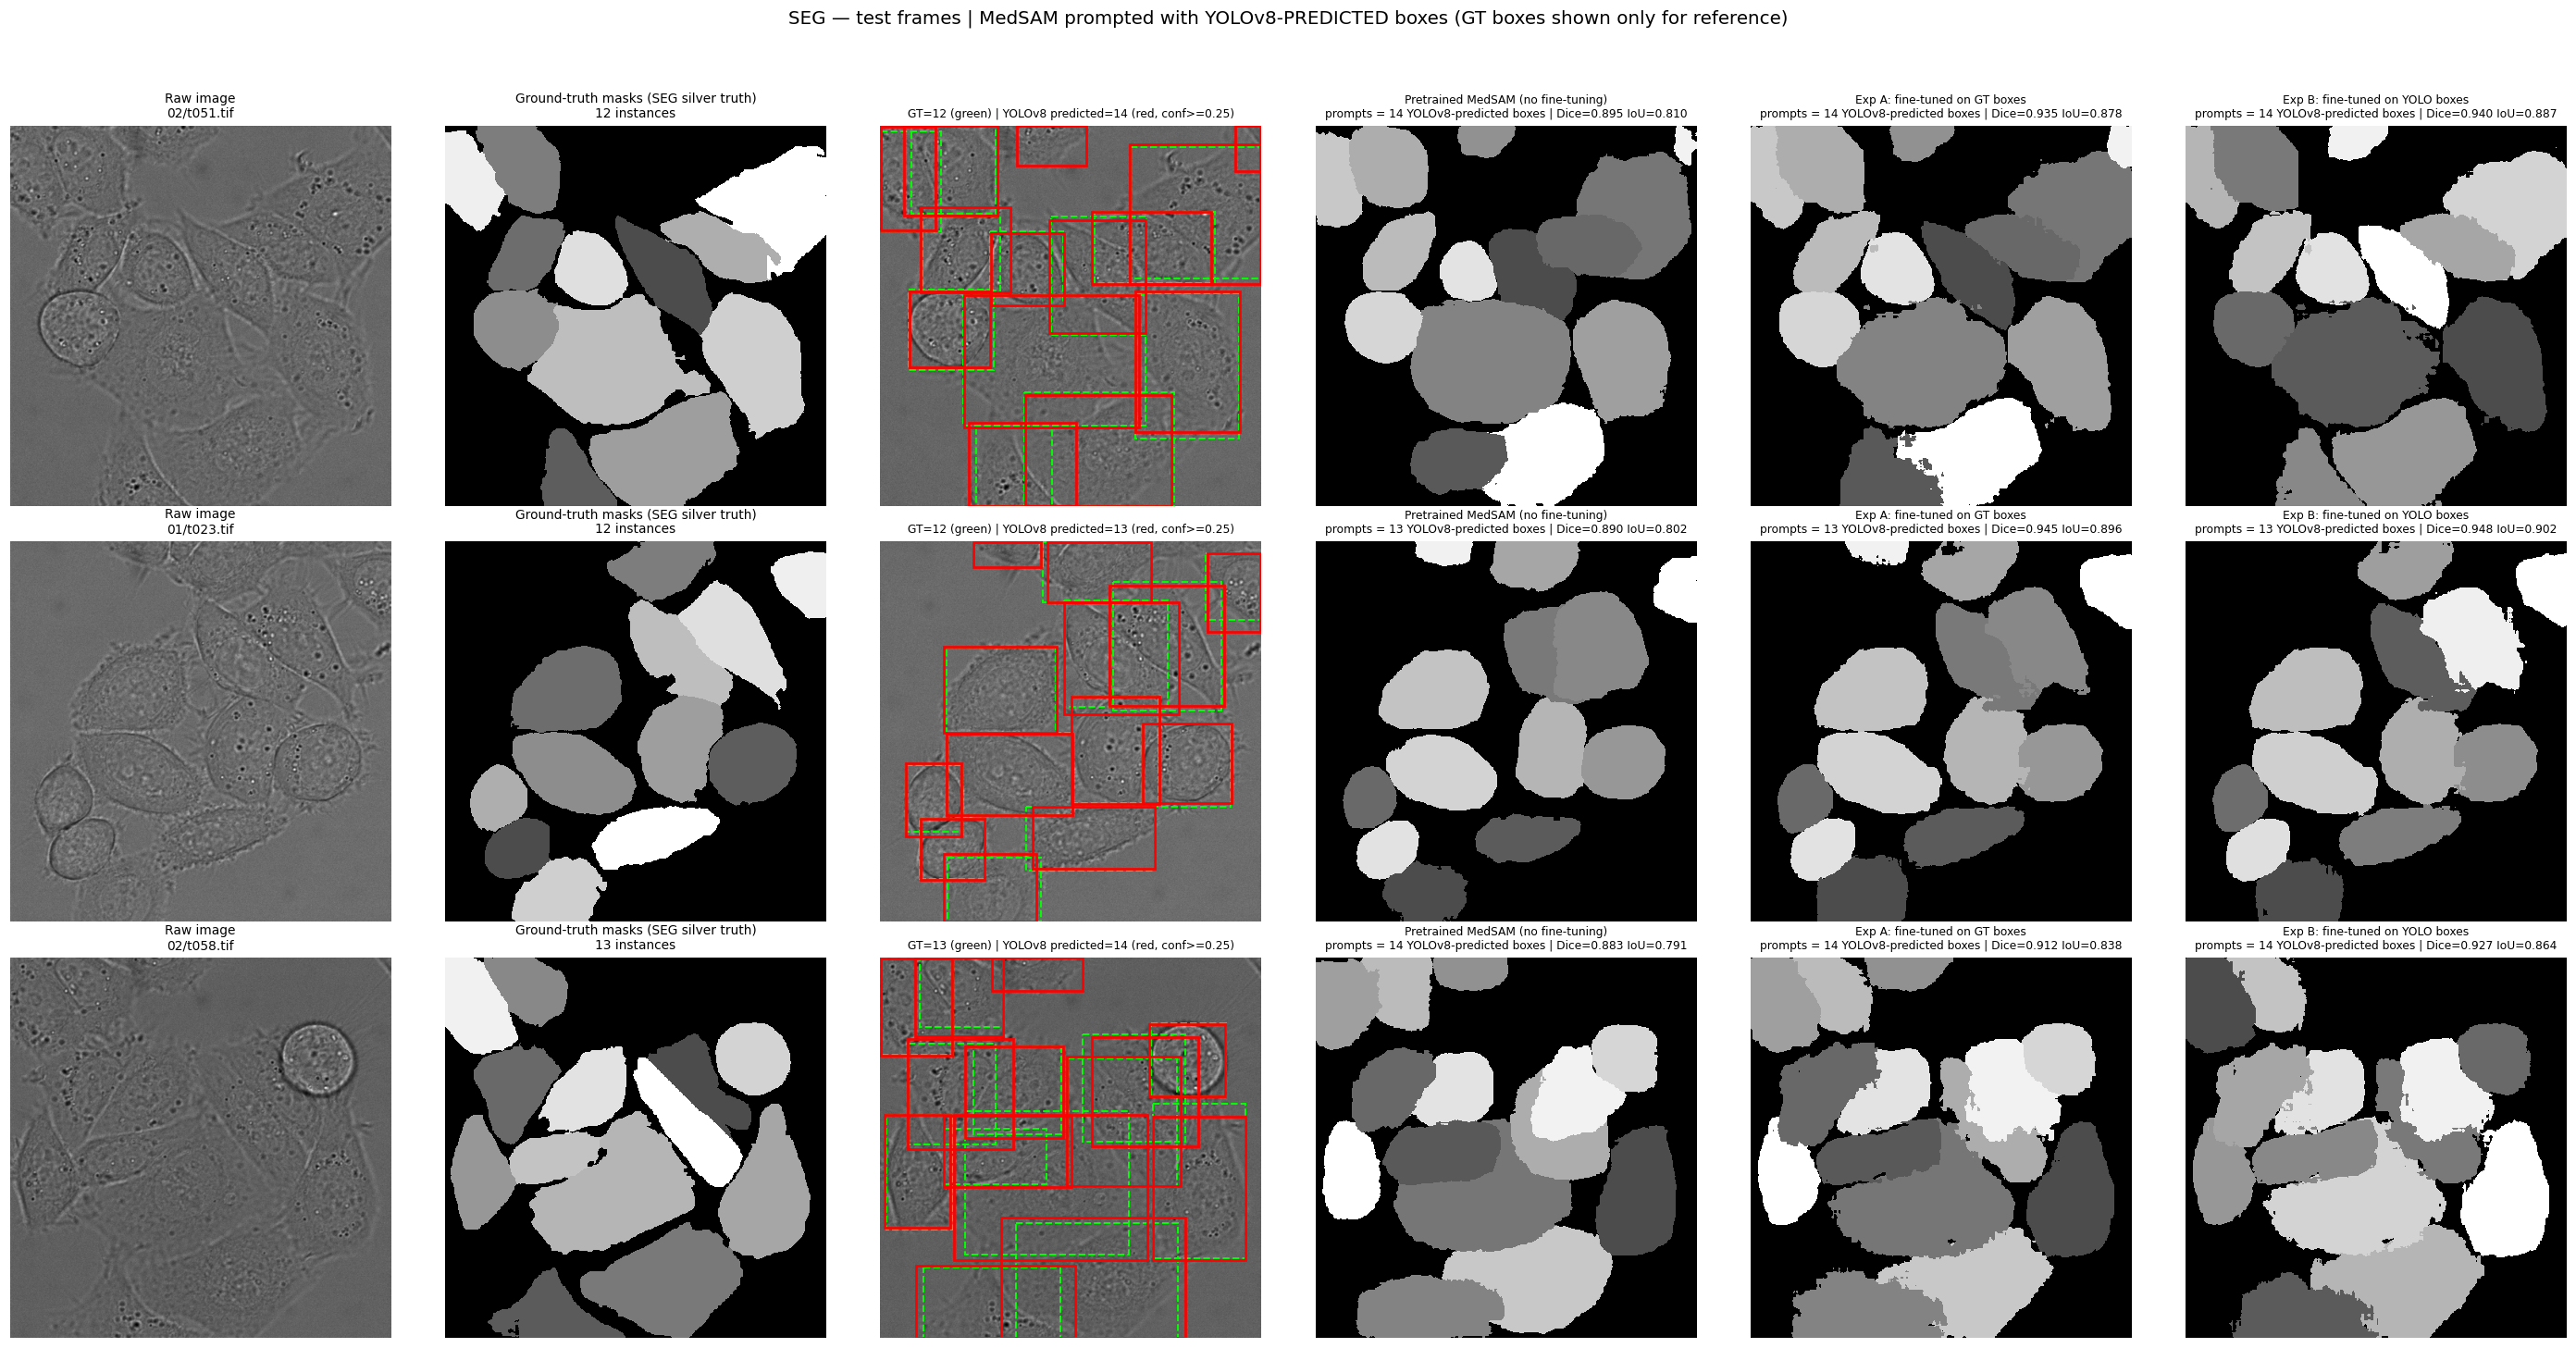

--- TRA : held-out TEST frames, MedSAM prompted by YOLOv8-PREDICTED boxes ---


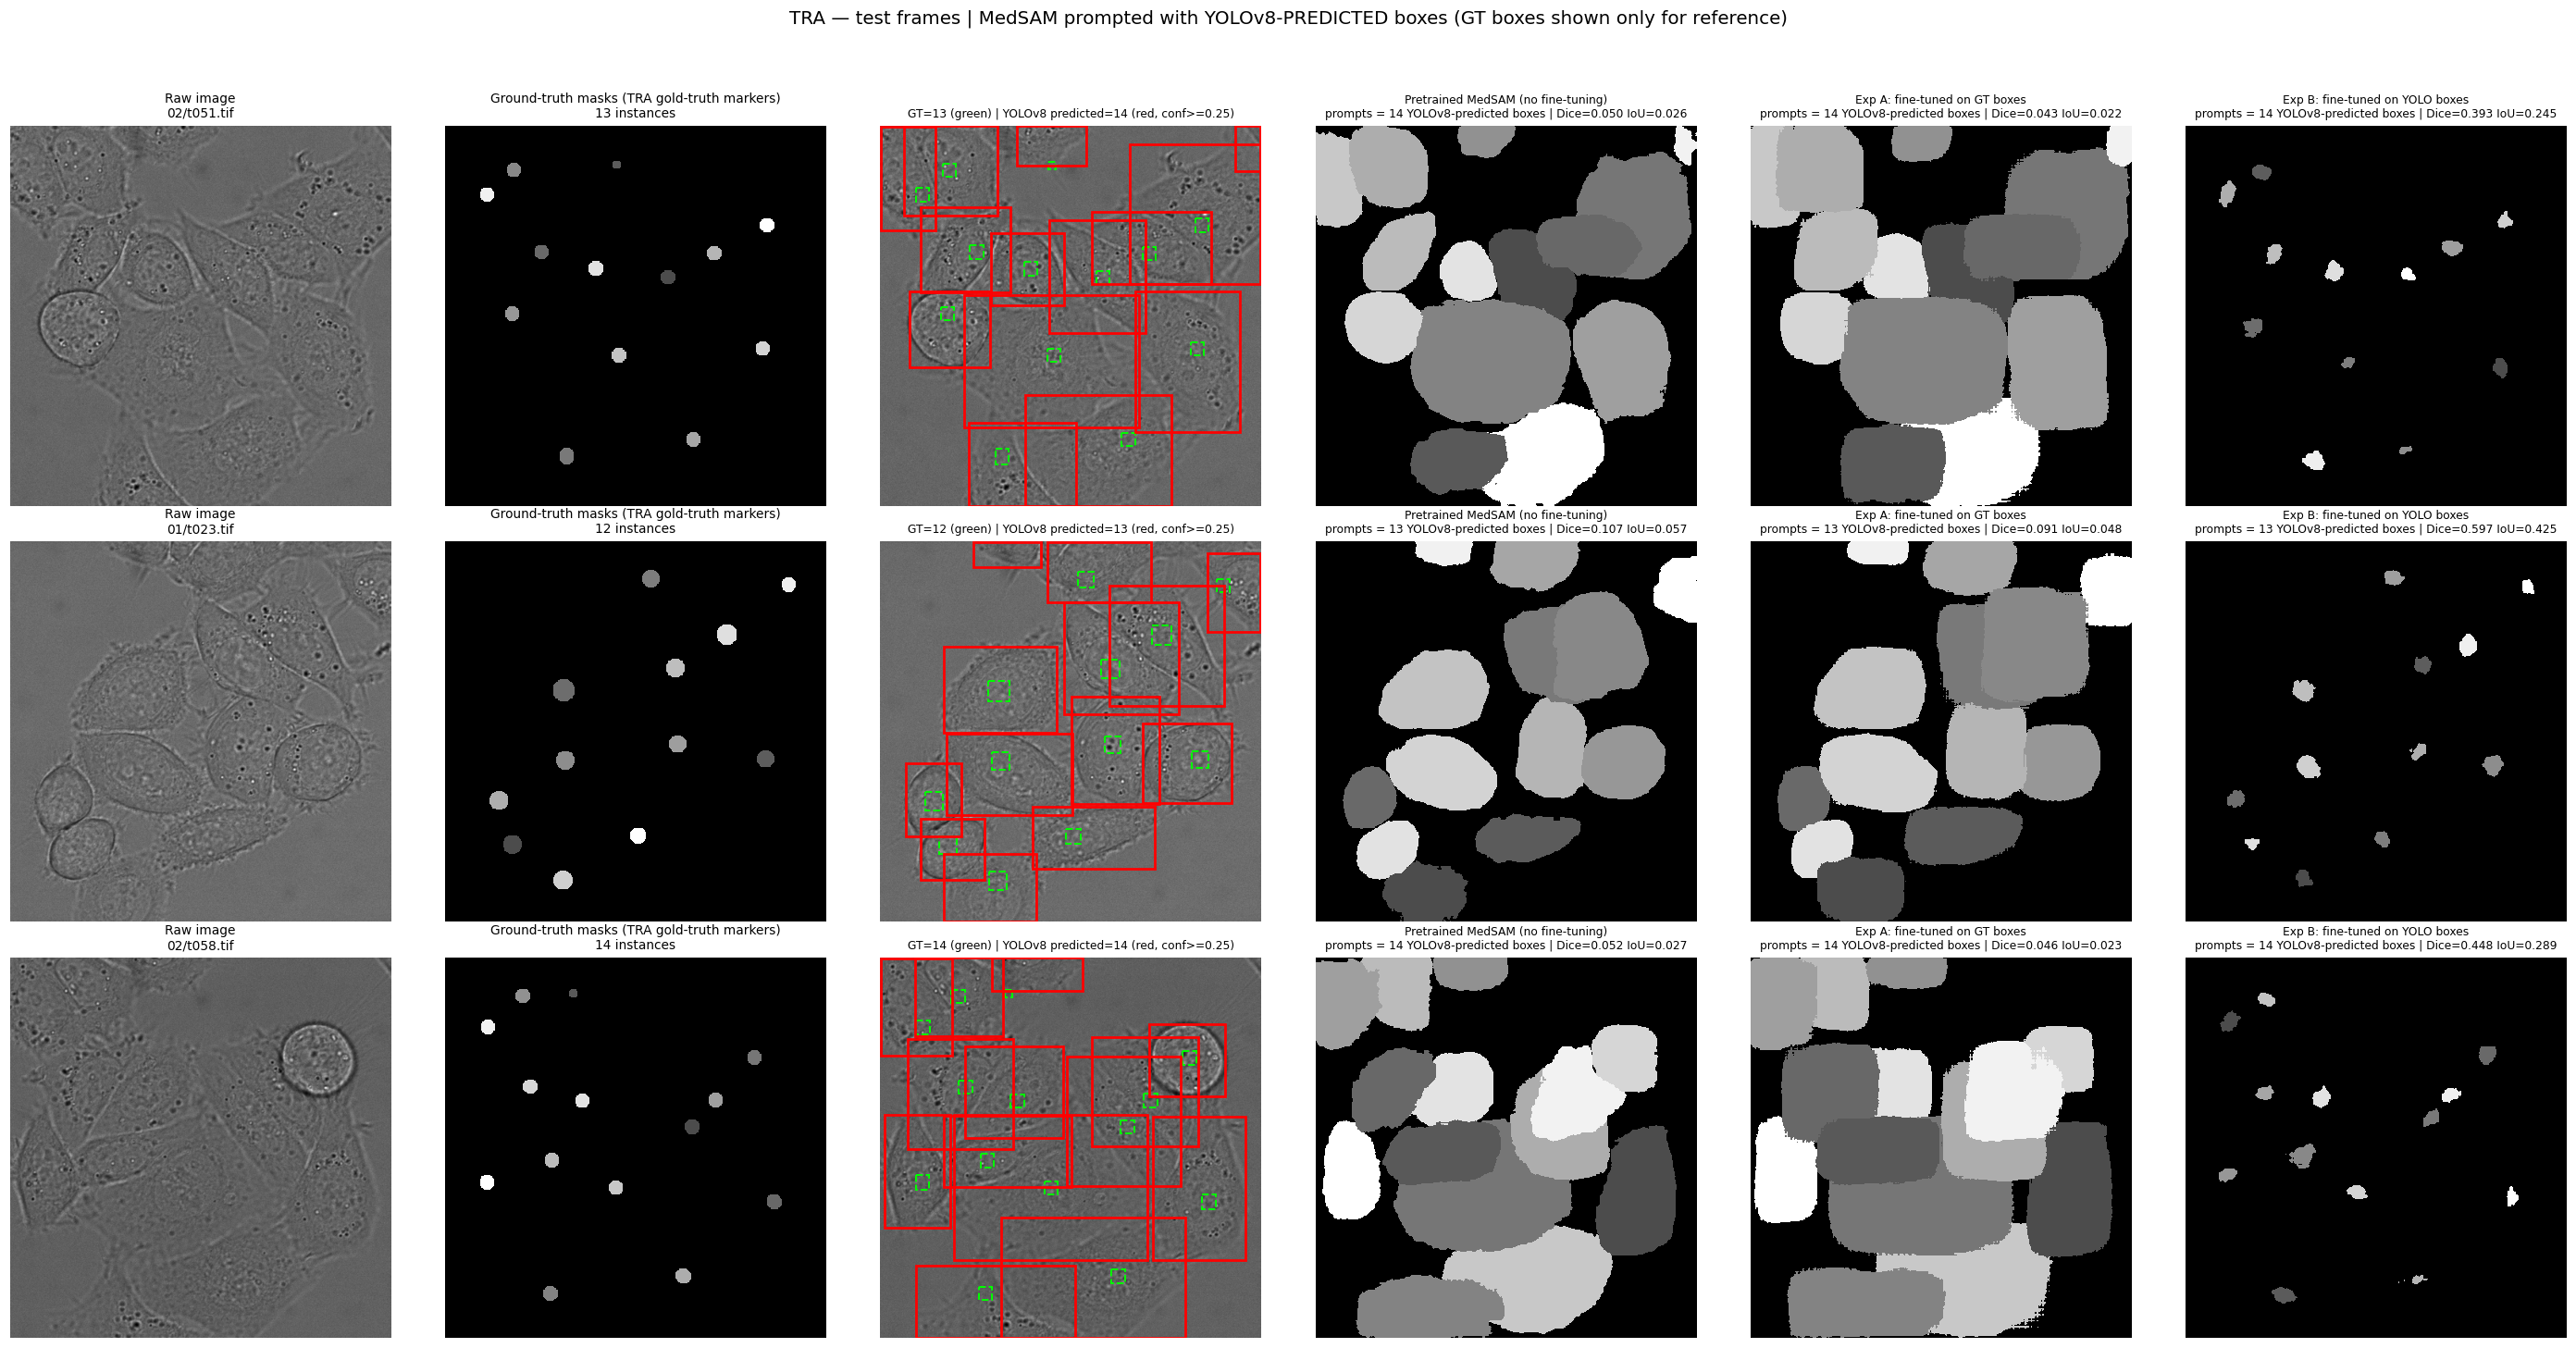

In [ ]:
## ── Cell 14 : Qualitative visualisation — REPLACEMENT ──────────────────────────────────────────────────────
## Old version prompted MedSAM with GT boxes only (no boxes shown at all). This one shows, per test frame:
##   raw image | GT masks | GT (green) vs YOLO-PREDICTED (red) boxes | MedSAM masks prompted by those PREDICTED boxes
## Every title states the weights AND the prompt, and the Dice/IoU is against the GT union mask of that frame.

def instance_to_sharp_grayscale(inst_map):
    inst_map = inst_map.astype(np.int32)
    ids      = np.unique(inst_map); ids = ids[ids != 0]
    out      = np.zeros(inst_map.shape, dtype=float)
    if len(ids) == 0: return out
    levels   = np.linspace(1.0, 0.3, len(ids))
    np.random.default_rng(0).shuffle(levels)
    for uid, g in zip(ids, levels):
        out[inst_map == uid] = g
    return out

def masks_to_instance_map(masks):
    """(N,H,W) per-box masks -> one instance map (later boxes overwrite earlier ones on overlap, as before)."""
    inst = np.zeros(masks.shape[1:], np.int32)
    for k, m in enumerate(masks, 1): inst[m > 0] = k
    return inst

def show_final_pipeline(samples, task, models, title):
    """models: list of (label, model). Prompts are ALWAYS the YOLOv8-predicted boxes of this task."""
    _, imgsz, conf, mask_index, pred_fn = yolo_for(task)
    ncols = 3 + len(models)
    fig, ax = plt.subplots(len(samples), ncols, figsize=(4.3 * ncols, 4.4 * len(samples)), dpi=110, squeeze=False)
    for r, entry in enumerate(samples):
        img     = tiff.imread(entry[0]); H, W = img.shape[:2]
        gt_inst = tiff.imread(entry[mask_index]).astype(np.int32); gt_union = (gt_inst > 0).astype(np.uint8)
        gt_boxes = [b.tolist() for _, b in get_instance_boxes(gt_inst)]
        det = predict_yolo_detailed(yolo_for(task)[0], img.astype(np.float32), conf, imgsz)
        pboxes = det['boxes']; ok, probs = validate_boxes(pboxes, H, W)
        name = f"{os.path.basename(os.path.dirname(entry[0]))}/{os.path.basename(entry[0])}"
        ax[r][0].imshow(img, cmap='gray'); ax[r][0].set_title(f'Raw image\n{name}', fontsize=9)
        ax[r][1].imshow(instance_to_sharp_grayscale(gt_inst), cmap='gray', vmin=0, vmax=1, interpolation='none')
        ax[r][1].set_title(f"Ground-truth masks ({'SEG silver truth' if task == 'seg' else 'TRA gold-truth markers'})\n{len(gt_boxes)} instances", fontsize=9)
        draw_gt_pred(ax[r][2], img.astype(np.float32), gt_boxes, pboxes, det['scores'], show_scores=False,
                     title=f"GT={len(gt_boxes)} (green) | YOLOv8 predicted={len(pboxes)} (red, conf>={conf})" + ('' if ok else ' ⚠invalid'),
                     empty_note=f"NO PREDICTED BOXES (conf>={conf}; raw={det['n_raw']})")
        for c, (lbl, mdl) in enumerate(models, 3):
            masks = medsam_predict_boxes(mdl, img, pboxes)
            union = masks.max(0) if len(masks) else np.zeros((H, W), np.uint8)
            d, i, _, _ = metrics(union, gt_union)
            ax[r][c].imshow(instance_to_sharp_grayscale(masks_to_instance_map(masks)) if len(masks) else np.zeros((H, W)),
                            cmap='gray', vmin=0, vmax=1, interpolation='none')
            if len(pboxes) == 0:
                ax[r][c].text(0.5, 0.5, '0 predicted boxes\n→ nothing to segment', transform=ax[r][c].transAxes, color='red',
                              ha='center', va='center', fontsize=10, bbox=dict(facecolor='white', alpha=0.85, edgecolor='red'))
            ax[r][c].set_title(f"{lbl}\nprompts = {len(pboxes)} YOLOv8-predicted boxes | Dice={d:.3f} IoU={i:.3f}", fontsize=8)
        for a in ax[r]: a.axis('off')
    plt.suptitle(title, fontsize=13, y=1.0); plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

for task, samples in [('seg', test_seg[:3]), ('tra', test_tra[:3])]:
    mods = [('Pretrained MedSAM (no fine-tuning)', medsam)]
    if globals().get(f'medsam_expA_{task}') is not None: mods.append(('Exp A: fine-tuned on GT boxes', globals()[f'medsam_expA_{task}']))
    if globals().get(f'medsam_expB_{task}') is not None: mods.append(('Exp B: fine-tuned on YOLO boxes', globals()[f'medsam_expB_{task}']))
    print(f'--- {task.upper()} : held-out TEST frames, MedSAM prompted by YOLOv8-PREDICTED boxes ---')
    show_final_pipeline(samples, task, mods,
        title=f'{task.upper()} — test frames | MedSAM prompted with YOLOv8-PREDICTED boxes (GT boxes shown only for reference)')


## Cell 15 — Tracking evaluation (does a cell keep its identity from frame to frame?)  **[NEW]**

Dice against 18-px markers is a *segmentation-style* number; it does not measure tracking. This cell measures tracking directly with the TRA gold-truth **IDs**:

1. per frame: cell masks from **YOLOv8 (SEG) boxes → MedSAM** (and, as an upper bound for the linker, the SEG silver-truth masks)
2. link masks frame *t* → *t+1* (Hungarian assignment on mask IoU, centroid-distance fallback) → predicted track IDs
3. give each predicted mask the gold ID of the marker inside it
4. score **marker recall**, **link recall** (headline), link precision, association accuracy, **ID switches**

Rows are reported for *all* consecutive frames (optimistic: neighbouring frames were seen in training) and for **unseen frames only**
(both frames of a pair in val/test). The ORACLE row shows what the linker achieves with perfect masks; the FULL row is the real system.
Needs only the SEG detector and the SEG MedSAM weights from Cell 12 — no TRA model.


MedSAM weights used for tracking masks: Exp B-SEG (fine-tuned on YOLO boxes)


ORACLE masks (SEG silver truth) -> linker only | seq 01:   0%|          | 0/84 [00:00<?, ?it/s]

ORACLE masks (SEG silver truth) -> linker only | seq 02:   0%|          | 0/84 [00:00<?, ?it/s]


=== TRACKING: ORACLE masks (linker quality with perfect segmentation) ===
                                       setting                                                                subset  n_frames  n_pairs  marker_recall  link_recall  link_precision  assoc_acc  id_switches  id_switches_per_pair
ORACLE masks (SEG silver truth) -> linker only ALL consecutive frames (optimistic: neighbours were seen in training)       168      166          0.973        0.962           0.992      0.992            2                 0.012
ORACLE masks (SEG silver truth) -> linker only                      UNSEEN frames only (val/test, never in training)        68       31          0.973        0.956           0.987      0.987            0                 0.000


FULL pipeline: YOLOv8 boxes -> MedSAM -> linker | seq 01:   0%|          | 0/84 [00:00<?, ?it/s]

FULL pipeline: YOLOv8 boxes -> MedSAM -> linker | seq 02:   0%|          | 0/84 [00:00<?, ?it/s]


=== TRACKING RESULTS (TRA gold-truth IDs) ===
                                        setting                                                                subset  n_frames  n_pairs  marker_recall  link_recall  link_precision  assoc_acc  id_switches  id_switches_per_pair
 ORACLE masks (SEG silver truth) -> linker only ALL consecutive frames (optimistic: neighbours were seen in training)       168      166          0.973        0.962           0.992      0.992            2                 0.012
 ORACLE masks (SEG silver truth) -> linker only                      UNSEEN frames only (val/test, never in training)        68       31          0.973        0.956           0.987      0.987            0                 0.000
FULL pipeline: YOLOv8 boxes -> MedSAM -> linker ALL consecutive frames (optimistic: neighbours were seen in training)       168      166          0.941        0.931           0.863      0.992            1                 0.006
FULL pipeline: YOLOv8 boxes -> MedSAM -> link

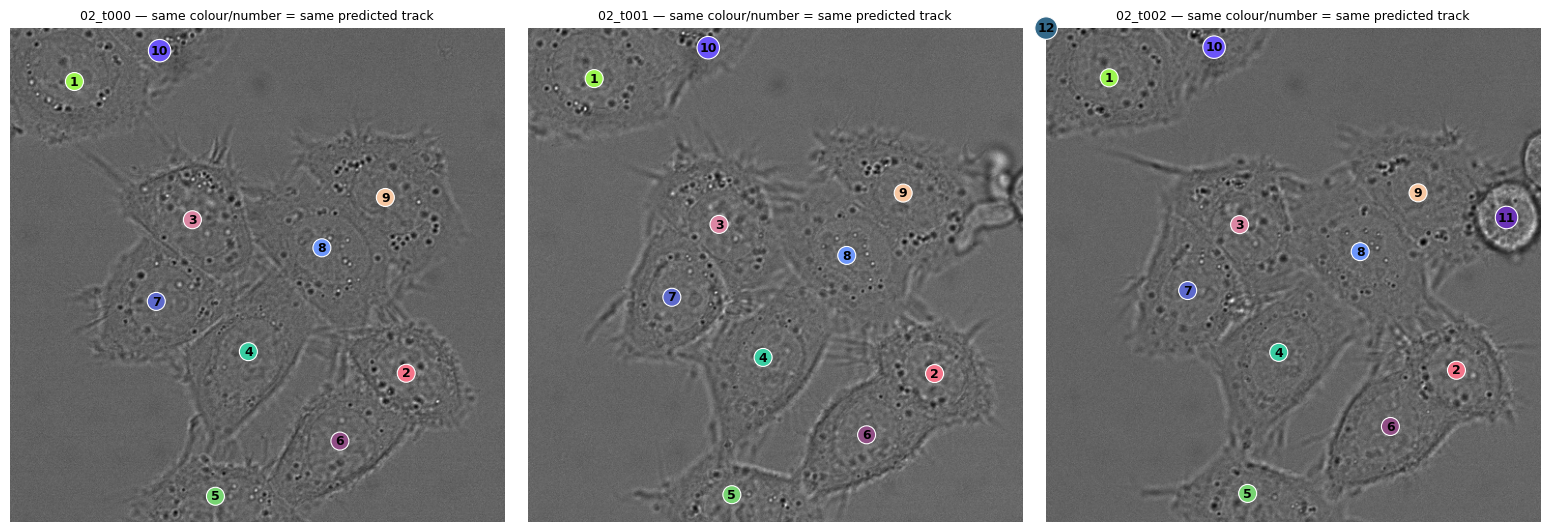

In [ ]:
## ── Cell 15 : TRACKING evaluation (detect → segment → link across frames → compare with TRA gold-truth IDs) ──
## Why this cell exists: "Dice against the 18-px TRA markers" is NOT tracking. Tracking = keeping the same identity on a
## cell from frame t to t+1. The TRA gold truth gives every cell an ID that is constant over time, so we can check that directly:
##   1. per frame: cell masks  (YOLOv8-SEG boxes -> MedSAM masks)   OR   oracle SEG silver-truth masks (isolates the linker)
##   2. link masks t -> t+1 (Hungarian assignment on mask IoU, centroid-distance fallback) -> predicted track IDs
##   3. give every predicted mask the TRA gold ID of the marker that lies inside it
##   4. score: marker detection recall, link recall (GT links recovered), association accuracy, ID switches
from scipy.optimize import linear_sum_assignment

TRACK_MIN_IOU  = 0.10   # mask IoU needed to link two masks directly
TRACK_MAX_DIST = 40     # px: if IoU is lower, still allow a (weaker) link when centroids are this close
TRACK_BOX_CONF = None   # None -> YOLO_CONF_SEG

def _mask_stats(masks):
    n = len(masks)
    if n == 0: return np.zeros((0, 2)), np.zeros(0)
    flat = masks.reshape(n, -1).astype(np.float32)
    area = flat.sum(1)
    ys, xs = np.indices(masks.shape[1:])
    cy = (flat @ ys.reshape(-1).astype(np.float32)) / np.maximum(area, 1)
    cx = (flat @ xs.reshape(-1).astype(np.float32)) / np.maximum(area, 1)
    return np.stack([cy, cx], 1), area

def link_masks(ma, mb, min_iou=TRACK_MIN_IOU, max_dist=TRACK_MAX_DIST):
    """Link masks of frame t (ma: N,H,W) to frame t+1 (mb: M,H,W). Returns list of (i, j). One-to-one (Hungarian)."""
    if len(ma) == 0 or len(mb) == 0: return []
    fa = ma.reshape(len(ma), -1).astype(np.float32); fb = mb.reshape(len(mb), -1).astype(np.float32)
    inter = fa @ fb.T; union = fa.sum(1)[:, None] + fb.sum(1)[None, :] - inter
    iou = inter / np.maximum(union, 1)
    ca, _ = _mask_stats(ma); cb, _ = _mask_stats(mb)
    dist = np.linalg.norm(ca[:, None, :] - cb[None, :, :], axis=2)
    score = np.where(iou >= min_iou, iou, np.where(dist < max_dist, 0.05 * (1 - dist / max_dist), 0.0))
    r, c = linear_sum_assignment(-score)
    return [(int(i), int(j)) for i, j in zip(r, c) if score[i, j] > 0]

def run_tracker(masks_per_frame):
    """List (time-ordered) of (N_t,H,W) mask arrays -> list of predicted track-ID arrays (one ID per mask)."""
    nid, out = 1, []
    for t, m in enumerate(masks_per_frame):
        tid = np.zeros(len(m), int)
        if t > 0:
            for i, j in link_masks(masks_per_frame[t - 1], m): tid[j] = out[t - 1][i]
        for j in range(len(m)):
            if tid[j] == 0: tid[j] = nid; nid += 1
        out.append(tid)
    return out

def assign_gt_ids(masks, marker_map, min_frac=0.5):
    """Give each predicted mask the TRA gold ID whose marker lies (>= min_frac of its pixels) inside it.
    Returns (gt_id_per_mask [0 = no marker], n_markers, n_markers_found)."""
    ids = np.unique(marker_map); ids = ids[ids != 0]
    gt = np.zeros(len(masks), int); best = np.zeros(len(masks))
    for g in ids:
        if len(masks) == 0: break
        ys, xs = np.nonzero(marker_map == g)
        frac = masks[:, ys, xs].mean(1)
        j = int(np.argmax(frac))
        if frac[j] >= min_frac and frac[j] > best[j]:      # a mask can carry ONE marker; a 2nd marker in it = merged cells -> missed
            gt[j] = g; best[j] = frac[j]
    found = len(set(gt[gt > 0]))
    return gt, len(ids), found

def score_sequence(recs):
    """recs: time-ordered list of dict(key, unseen, tid, gt, n_markers, n_found). Returns (frame_rows, pair_rows)."""
    frame_rows = [dict(key=r['key'], unseen=r['unseen'], n_markers=r['n_markers'], n_found=r['n_found']) for r in recs]
    pair_rows = []
    for a, b in zip(recs[:-1], recs[1:]):
        ga = {g: i for i, g in enumerate(a['gt']) if g > 0}; gb = {g: j for j, g in enumerate(b['gt']) if g > 0}
        gt_links = set(a['present']) & set(b['present'])                      # IDs that really continue t -> t+1
        both = set(ga) & set(gb)                                              # ...and were found in BOTH frames
        rec = sum(1 for g in gt_links if g in both and a['tid'][ga[g]] == b['tid'][gb[g]])
        idsw = sum(1 for g in both if a['tid'][ga[g]] != b['tid'][gb[g]])     # same cell, different predicted track
        t_a = {t: i for i, t in enumerate(a['tid'])}
        pred_links = [(t_a[t], j) for j, t in enumerate(b['tid']) if t in t_a]
        ok  = sum(1 for i, j in pred_links if a['gt'][i] > 0 and a['gt'][i] == b['gt'][j])
        grd = sum(1 for i, j in pred_links if a['gt'][i] > 0 and b['gt'][j] > 0)
        pair_rows.append(dict(key=b['key'], unseen=a['unseen'] and b['unseen'], n_gt_links=len(gt_links), recovered=rec,
                              both_found=len(both & gt_links), idsw=idsw, n_pred_links=len(pred_links), correct_links=ok, links_on_gt=grd))
    return frame_rows, pair_rows

def summarise_tracking(frame_rows, pair_rows, label):
    f, p = pd.DataFrame(frame_rows), pd.DataFrame(pair_rows)
    out = []
    for nm, fm, pm in [('ALL consecutive frames (optimistic: neighbours were seen in training)', f, p),
                       ('UNSEEN frames only (val/test, never in training)', f[f.unseen], p[p.unseen])]:
        if len(pm) == 0 or len(fm) == 0:
            out.append(dict(setting=label, subset=nm, n_frames=len(fm), n_pairs=0)); continue
        out.append(dict(setting=label, subset=nm, n_frames=len(fm), n_pairs=len(pm),
                        marker_recall=fm.n_found.sum() / max(fm.n_markers.sum(), 1),
                        link_recall=pm.recovered.sum() / max(pm.n_gt_links.sum(), 1),
                        link_precision=pm.correct_links.sum() / max(pm.n_pred_links.sum(), 1),
                        assoc_acc=pm.correct_links.sum() / max(pm.links_on_gt.sum(), 1),
                        id_switches=int(pm.idsw.sum()), id_switches_per_pair=pm.idsw.sum() / len(pm)))
    return pd.DataFrame(out)

# ── glue to the notebook's data ───────────────────────────────────────────────────────────────────────────
def build_sequences(pairs):
    """pairs_tra entries -> {seq: time-ordered list of entries with CONSECUTIVE frame numbers only (no gaps)}."""
    seqs = {}
    for e in pairs: seqs.setdefault(frame_seq(e), []).append(e)
    out = {}
    for s, es in seqs.items():
        es = sorted(es, key=frame_idx); run = [es[0]]
        for e in es[1:]:
            if frame_idx(e) == frame_idx(run[-1]) + 1: run.append(e)
            else: out.setdefault(s, []).append(run); run = [e]
        out.setdefault(s, []).append(run)
    return out

def frame_masks(entry, img, source, model):
    if source == 'oracle':
        if entry[1] is None: return None
        inst = tiff.imread(entry[1]).astype(np.int32); ids = np.unique(inst); ids = ids[ids != 0]
        return np.stack([(inst == i) for i in ids]).astype(np.uint8) if len(ids) else np.zeros((0,) + inst.shape, np.uint8)
    boxes = predict_boxes_seg(img.astype(np.float32), conf=TRACK_BOX_CONF)
    return medsam_predict_boxes(model, img, boxes)

def evaluate_tracking(pairs, train_pairs, source, model, label, max_frames=None):
    train_keys = {frame_key(e) for e in train_pairs}
    fr_all, pr_all = [], []
    for seq, runs in build_sequences(pairs).items():
        for run in runs:
            run = run[:max_frames] if max_frames else run
            recs, masks_list = [], []
            for e in tqdm(run, desc=f'{label} | seq {seq}', leave=False):
                img = tiff.imread(e[0]); m = frame_masks(e, img, source, model)
                if m is None: break
                marker_map = tiff.imread(e[2]).astype(np.int32)
                gt, nm, nf = assign_gt_ids(m, marker_map)
                present = [g for g in np.unique(marker_map) if g != 0]
                recs.append(dict(key=frame_key(e), unseen=frame_key(e) not in train_keys, gt=gt, present=present,
                                 n_markers=nm, n_found=nf)); masks_list.append(m)
            tids = run_tracker(masks_list)
            for r, t in zip(recs, tids): r['tid'] = t
            fr, pr = score_sequence(recs); fr_all += fr; pr_all += pr
    return summarise_tracking(fr_all, pr_all, label), recs, masks_list

tracking_model = globals().get('medsam_expB_seg') or medsam       # SEG-task MedSAM (Exp B) if available, else pretrained
print('MedSAM weights used for tracking masks:', 'Exp B-SEG (fine-tuned on YOLO boxes)' if globals().get('medsam_expB_seg') else 'pretrained')

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 80)
# 1) ORACLE first: needs no detector / MedSAM, so you always get a tracking number even if step 2 fails
res_oracle, _, _ = evaluate_tracking(pairs_tra, train_tra, 'oracle', None, 'ORACLE masks (SEG silver truth) -> linker only')
print('\n=== TRACKING: ORACLE masks (linker quality with perfect segmentation) ===')
print(res_oracle.round(3).to_string(index=False))

# 2) FULL pipeline: an error here no longer hides the oracle result
recs, mlist = [], []
try:
    res_full, recs, mlist = evaluate_tracking(pairs_tra, train_tra, 'yolo', tracking_model, 'FULL pipeline: YOLOv8 boxes -> MedSAM -> linker')
    track_table = pd.concat([res_oracle, res_full], ignore_index=True)
    print('\n=== TRACKING RESULTS (TRA gold-truth IDs) ===')
    print(track_table.round(3).to_string(index=False))
except Exception as ex:
    import traceback; traceback.print_exc()
    print('\u274c FULL pipeline failed (oracle result above is still valid):', repr(ex)[:300])
print('\nmarker_recall   : fraction of GT cells (TRA markers) that fall inside a predicted cell mask')
print('link_recall     : fraction of GT "same cell in t and t+1" links the tracker reproduced   (the headline tracking number)')
print('link_precision  : fraction of predicted links that join two masks carrying the SAME gold ID')
print('assoc_acc       : same, but only over links whose two ends both carry a gold ID (pure association accuracy)')
print('id_switches     : a GT cell found in both frames but given different predicted track IDs')
print('Read it as: ORACLE row = how good the LINKER is when segmentation is perfect; FULL row = what the whole system achieves.\n'
      'If ORACLE is high and FULL is low -> improve detection/segmentation. If ORACLE is low -> improve the linker.')

# ── picture: 3 consecutive frames, predicted track IDs drawn on the cells ─────────────────────────────────
def show_tracks(recs, masks_list, run_entries, k0=0, n=3):
    fig, axs = plt.subplots(1, n, figsize=(5.2 * n, 5.4))
    rng = np.random.default_rng(1); cols = {}
    for ax, k in zip(np.atleast_1d(axs), range(k0, k0 + n)):
        img = tiff.imread(run_entries[k][0]); ax.imshow(img, cmap='gray'); ax.axis('off')
        cen, _ = _mask_stats(masks_list[k])
        for (cy, cx), tid, gt in zip(cen, recs[k]['tid'], recs[k]['gt']):
            c = cols.setdefault(int(tid), tuple(rng.uniform(0.2, 1, 3)))
            ax.text(cx, cy, str(int(tid)), color='k', fontsize=9, ha='center', va='center', weight='bold',
                    bbox=dict(boxstyle='circle,pad=0.2', fc=c, ec='w', lw=0.8))
        ax.set_title(f"{recs[k]['key']} — same colour/number = same predicted track", fontsize=9)
    plt.tight_layout(); plt.show()

_runs = [r for runs in build_sequences(pairs_tra).values() for r in runs]
if len(recs) >= 3 and len(mlist) >= 3: show_tracks(recs, mlist, _runs[-1], k0=0, n=3)
